In [1]:
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely import contains_xy

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load Natural Earth country boundaries

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

countries = gpd.read_file(boundary_path)

print("Number of countries:", len(countries))
print("Boundary data loaded successfully.")

Number of countries: 258
Boundary data loaded successfully.


In [3]:
era5_paths = {
    "India": "../data/raw/era5_india/data_stream-moda.nc",
    "United States of America": "../data/raw/era5_usa/data_stream-moda.nc",
    "China": "../data/raw/era5_china/data_stream-moda.nc",
    "Brazil": "../data/raw/era5_brazil/data_stream-moda.nc",
    "Australia": "../data/raw/era5_australia/data_stream-moda.nc"
}

print("ERA5 country paths configured:")
for country, path in era5_paths.items():
    print(country, "->", path)

ERA5 country paths configured:
India -> ../data/raw/era5_india/data_stream-moda.nc
United States of America -> ../data/raw/era5_usa/data_stream-moda.nc
China -> ../data/raw/era5_china/data_stream-moda.nc
Brazil -> ../data/raw/era5_brazil/data_stream-moda.nc
Australia -> ../data/raw/era5_australia/data_stream-moda.nc


In [4]:
# Reusable function for processing one country

def process_country(nc_path, country_name):

    print(f"\nProcessing {country_name}...")

    # --------------------------------------------------------
    # Load ERA5-Land dataset
    # --------------------------------------------------------

    ds = xr.open_dataset(nc_path)

    # --------------------------------------------------------
    # Get country boundary
    # --------------------------------------------------------

    country = countries[
        countries["ADMIN"] == country_name
    ].geometry.iloc[0]

    # --------------------------------------------------------
    # Create latitude-longitude grid
    # --------------------------------------------------------

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    # --------------------------------------------------------
    # Create country mask
    # --------------------------------------------------------

    country_mask = contains_xy(
        country,
        lon,
        lat
    )

    # --------------------------------------------------------
    # Extract temperature and precipitation
    # --------------------------------------------------------

    temperature = ds["t2m"].where(country_mask)
    precipitation = ds["tp"].where(country_mask)

    # --------------------------------------------------------
    # Latitude weighting
    # --------------------------------------------------------

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    # --------------------------------------------------------
    # Area-weighted monthly temperature
    # --------------------------------------------------------

    monthly_temperature = (
        temperature
        .weighted(weights)
        .mean(dim=("latitude", "longitude"))
    )

    # Convert Kelvin to Celsius
    monthly_temperature_C = (
        monthly_temperature - 273.15
    )

    # --------------------------------------------------------
    # Area-weighted monthly precipitation
    # --------------------------------------------------------

    monthly_precipitation = (
        precipitation
        .weighted(weights)
        .mean(dim=("latitude", "longitude"))
    )

    # ERA5-Land monthly averaged precipitation:
    # convert m/day -> mm/month

    days = ds["valid_time"].dt.days_in_month

    monthly_precipitation_mm = (
        monthly_precipitation
        * 1000
        * days
    )

    # --------------------------------------------------------
    # Create monthly DataFrame
    # --------------------------------------------------------

    monthly_df = pd.DataFrame({
        "date": pd.to_datetime(
            ds["valid_time"].values
        ),
        "temperature_C": monthly_temperature_C.values,
        "precipitation_mm": monthly_precipitation_mm.values
    })

    monthly_df["country"] = country_name
    monthly_df["year"] = monthly_df["date"].dt.year
    monthly_df["month"] = monthly_df["date"].dt.month

    # --------------------------------------------------------
    # Create annual climate table
    # --------------------------------------------------------

    annual_df = (
        monthly_df
        .groupby(
            ["country", "year"],
            as_index=False
        )
        .agg(
            temperature_C=(
                "temperature_C",
                "mean"
            ),
            precipitation_mm=(
                "precipitation_mm",
                "sum"
            )
        )
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    months_per_year = (
        monthly_df
        .groupby("year")["month"]
        .count()
    )

    missing_years = months_per_year[
        months_per_year != 12
    ]

    if len(missing_years) == 0:
        print("✓ All years contain 12 months.")
    else:
        print("⚠ Missing months detected:")
        print(missing_years)

    print(
        f"✓ Monthly rows: {len(monthly_df)}"
    )

    print(
        f"✓ Annual rows: {len(annual_df)}"
    )

    # Close dataset
    ds.close()

    return monthly_df, annual_df

In [5]:
# Test the climate-processing function on China

china_monthly, china_annual = process_country(
    era5_paths["China"],
    "China"
)

print("\nChina annual climate data:")
print(china_annual.head())


Processing China...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24

China annual climate data:
  country  year  temperature_C  precipitation_mm
0   China  2000       6.231737        848.598480
1   China  2001       6.624892        797.347404
2   China  2002       6.820885        852.146783
3   China  2003       6.606007        818.175214
4   China  2004       6.817417        763.717531


In [6]:
# Process all five countries

india_monthly, india_annual = process_country(
    era5_paths["India"],
    "India"
)

usa_monthly, usa_annual = process_country(
    era5_paths["United States of America"],
    "United States of America"
)

china_monthly, china_annual = process_country(
    era5_paths["China"],
    "China"
)

brazil_monthly, brazil_annual = process_country(
    era5_paths["Brazil"],
    "Brazil"
)

australia_monthly, australia_annual = process_country(
    era5_paths["Australia"],
    "Australia"
)


Processing India...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24

Processing United States of America...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24

Processing China...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24

Processing Brazil...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24

Processing Australia...
✓ All years contain 12 months.
✓ Monthly rows: 288
✓ Annual rows: 24


In [7]:
# Combine monthly climate data for all five countries

climate_monthly_all = pd.concat(
    [
        india_monthly,
        usa_monthly,
        china_monthly,
        brazil_monthly,
        australia_monthly
    ],
    ignore_index=True
)

# Sort by country, year and month
climate_monthly_all = climate_monthly_all.sort_values(
    ["country", "year", "month"]
).reset_index(drop=True)

print("Monthly climate dataset:")
print("Rows:", len(climate_monthly_all))
print("Columns:", list(climate_monthly_all.columns))

print("\nRows per country:")
print(
    climate_monthly_all
    .groupby("country")
    .size()
)

print("\nFirst 10 rows:")
print(climate_monthly_all.head(10))

Monthly climate dataset:
Rows: 1440
Columns: ['date', 'temperature_C', 'precipitation_mm', 'country', 'year', 'month']

Rows per country:
country
Australia                   288
Brazil                      288
China                       288
India                       288
United States of America    288
dtype: int64

First 10 rows:
        date  temperature_C  precipitation_mm    country  year  month
0 2000-01-01      26.628804         71.271150  Australia  2000      1
1 2000-02-01      26.353964        142.691721  Australia  2000      2
2 2000-03-01      24.443783         99.009576  Australia  2000      3
3 2000-04-01      21.107447         63.728725  Australia  2000      4
4 2000-05-01      16.306845         19.535323  Australia  2000      5
5 2000-06-01      13.971257         12.756070  Australia  2000      6
6 2000-07-01      14.749803         10.757223  Australia  2000      7
7 2000-08-01      15.888814         15.084992  Australia  2000      8
8 2000-09-01      21.352591        

In [8]:
# Combine annual climate data for all five countries

climate_annual_all = pd.concat(
    [
        india_annual,
        usa_annual,
        china_annual,
        brazil_annual,
        australia_annual
    ],
    ignore_index=True
)

# Sort by country and year
climate_annual_all = climate_annual_all.sort_values(
    ["country", "year"]
).reset_index(drop=True)

print("Annual climate dataset:")
print("Rows:", len(climate_annual_all))
print("Columns:", list(climate_annual_all.columns))

print("\nRows per country:")
print(
    climate_annual_all
    .groupby("country")
    .size()
)

print("\nFirst 10 rows:")
print(climate_annual_all.head(10))

Annual climate dataset:
Rows: 120
Columns: ['country', 'year', 'temperature_C', 'precipitation_mm']

Rows per country:
country
Australia                   24
Brazil                      24
China                       24
India                       24
United States of America    24
dtype: int64

First 10 rows:
     country  year  temperature_C  precipitation_mm
0  Australia  2000      21.250271        654.042290
1  Australia  2001      21.535439        498.924558
2  Australia  2002      22.602782        294.441683
3  Australia  2003      22.368579        435.325749
4  Australia  2004      22.253055        445.135495
5  Australia  2005      22.895866        352.496860
6  Australia  2006      22.251881        429.625445
7  Australia  2007      22.400766        467.760194
8  Australia  2008      22.171792        426.126723
9  Australia  2009      22.661571        414.545384


In [9]:
# Save the combined climate datasets

monthly_output_path = "../data/processed/climate_monthly_all.csv"
annual_output_path = "../data/processed/climate_annual_all.csv"

climate_monthly_all.to_csv(
    monthly_output_path,
    index=False
)

climate_annual_all.to_csv(
    annual_output_path,
    index=False
)

print("Climate datasets saved successfully.")
print()
print("Monthly:", monthly_output_path)
print("Annual:", annual_output_path)

Climate datasets saved successfully.

Monthly: ../data/processed/climate_monthly_all.csv
Annual: ../data/processed/climate_annual_all.csv


In [10]:
# Load the raw FAOSTAT crop-yield data

faostat_path = "../data/raw/faostat_crop_yield_raw.csv"

yield_raw = pd.read_csv(faostat_path)

print("Raw FAOSTAT dataset")
print("Rows:", len(yield_raw))
print("Columns:", list(yield_raw.columns))

print("\nCountries:")
print(yield_raw["Area"].unique())

print("\nCrops:")
print(yield_raw["Item"].unique())

print("\nYears:")
print(
    yield_raw["Year"].min(),
    "to",
    yield_raw["Year"].max()
)

print("\nElements:")
print(yield_raw["Element"].unique())

print("\nUnits:")
print(yield_raw["Unit"].unique())

Raw FAOSTAT dataset
Rows: 375
Columns: ['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']

Countries:
<StringArray>
['Australia', 'Brazil', 'China', 'India', 'United States of America']
Length: 5, dtype: str

Crops:
<StringArray>
['Maize (corn)', 'Rice', 'Wheat']
Length: 3, dtype: str

Years:
2000 to 2024

Elements:
<StringArray>
['Yield']
Length: 1, dtype: str

Units:
<StringArray>
['kg/ha']
Length: 1, dtype: str


In [11]:
# Clean the FAOSTAT crop-yield data
# Analysis period: 2000-2023

selected_countries = [
    "Australia",
    "Brazil",
    "China",
    "India",
    "United States of America"
]

selected_crops = [
    "Maize (corn)",
    "Rice",
    "Wheat"
]

yield_clean = yield_raw[
    (yield_raw["Area"].isin(selected_countries)) &
    (yield_raw["Item"].isin(selected_crops)) &
    (yield_raw["Element"] == "Yield") &
    (yield_raw["Unit"] == "kg/ha") &
    (yield_raw["Year"].between(2000, 2023))
].copy()

# Keep only the columns needed for our analysis
yield_clean = yield_clean[
    ["Area", "Item", "Year", "Unit", "Value", "Flag"]
].copy()

# Rename columns
yield_clean = yield_clean.rename(
    columns={
        "Area": "country",
        "Item": "crop",
        "Year": "year",
        "Unit": "unit",
        "Value": "yield_kg_ha",
        "Flag": "flag"
    }
)

# Sort the dataset
yield_clean = yield_clean.sort_values(
    ["country", "crop", "year"]
).reset_index(drop=True)

# Display basic checks
print("Clean FAOSTAT yield dataset")
print("Rows:", len(yield_clean))
print("Columns:", list(yield_clean.columns))

print("\nRows per country:")
print(yield_clean.groupby("country").size())

print("\nRows per crop:")
print(yield_clean.groupby("crop").size())

print("\nYear range:")
print(yield_clean["year"].min(), "to", yield_clean["year"].max())

print("\nMissing values:")
print(yield_clean.isna().sum())

print("\nFirst 15 rows:")
print(yield_clean.head(15).to_string(index=False))

Clean FAOSTAT yield dataset
Rows: 360
Columns: ['country', 'crop', 'year', 'unit', 'yield_kg_ha', 'flag']

Rows per country:
country
Australia                   72
Brazil                      72
China                       72
India                       72
United States of America    72
dtype: int64

Rows per crop:
crop
Maize (corn)    120
Rice            120
Wheat           120
dtype: int64

Year range:
2000 to 2023

Missing values:
country        0
crop           0
year           0
unit           0
yield_kg_ha    0
flag           0
dtype: int64

First 15 rows:
  country         crop  year  unit  yield_kg_ha flag
Australia Maize (corn)  2000 kg/ha       4936.0    A
Australia Maize (corn)  2001 kg/ha       4647.1    A
Australia Maize (corn)  2002 kg/ha       5492.9    A
Australia Maize (corn)  2003 kg/ha       6257.0    A
Australia Maize (corn)  2004 kg/ha       5632.6    A
Australia Maize (corn)  2005 kg/ha       5798.3    A
Australia Maize (corn)  2006 kg/ha       5385.6    A
Austral

In [12]:
# Check FAOSTAT observation flags

print("FAOSTAT flags:")
print(yield_clean["flag"].value_counts(dropna=False))

print("\nRows with non-standard flags:")
print(
    yield_clean[
        yield_clean["flag"] != "A"
    ][
        ["country", "crop", "year", "yield_kg_ha", "flag"]
    ].to_string(index=False)
)

FAOSTAT flags:
flag
A    358
E      2
Name: count, dtype: int64

Rows with non-standard flags:
country         crop  year  yield_kg_ha flag
  China Maize (corn)  2001       4699.9    E
  China Maize (corn)  2002       4873.7    E


In [13]:
# Save the cleaned FAOSTAT yield dataset

yield_output_path = "../data/processed/yield_clean.csv"

yield_clean.to_csv(
    yield_output_path,
    index=False
)

print("Clean FAOSTAT yield dataset saved successfully.")
print("Path:", yield_output_path)
print("Rows:", len(yield_clean))

Clean FAOSTAT yield dataset saved successfully.
Path: ../data/processed/yield_clean.csv
Rows: 360


In [14]:
# Calculate whole-period climate variability for each country

climate_variability = (
    climate_annual_all
    .groupby("country")
    .agg(
        mean_temperature_C=("temperature_C", "mean"),
        temperature_SD_C=("temperature_C", "std"),
        mean_precipitation_mm=("precipitation_mm", "mean"),
        precipitation_SD_mm=("precipitation_mm", "std")
    )
    .reset_index()
)

# Calculate precipitation coefficient of variation (CV)
climate_variability["precipitation_CV_percent"] = (
    climate_variability["precipitation_SD_mm"]
    / climate_variability["mean_precipitation_mm"]
    * 100
)

print("Climate variability by country:")
print(
    climate_variability.to_string(index=False)
)

Climate variability by country:
                 country  mean_temperature_C  temperature_SD_C  mean_precipitation_mm  precipitation_SD_mm  precipitation_CV_percent
               Australia           22.390895          0.534057             438.329500           104.067790                 23.741909
                  Brazil           24.820900          0.352325            1707.481093           254.703942                 14.916941
                   China            6.964911          0.389271             770.468995            89.856400                 11.662559
                   India           23.534058          0.254118            1235.413810           157.580552                 12.755285
United States of America           12.052694          0.533431             776.244067           104.556192                 13.469500


In [15]:
# Calculate yield instability for each country-crop combination

yield_instability_results = []

for (country, crop), group in yield_clean.groupby(["country", "crop"]):

    # Sort by year
    group = group.sort_values("year").copy()

    # Take logarithm of yield
    group["log_yield"] = np.log(group["yield_kg_ha"])

    # Fit a linear trend over time
    x = group["year"].values
    y = group["log_yield"].values

    slope, intercept = np.polyfit(x, y, 1)

    # Predicted log-yield from the trend
    group["trend_log_yield"] = intercept + slope * x

    # Residual = actual log-yield - trend log-yield
    group["yield_residual"] = (
        group["log_yield"] - group["trend_log_yield"]
    )

    # Standard deviation of residuals
    instability = group["yield_residual"].std()

    # Mean absolute deviation from trend, useful for interpretation
    mean_abs_deviation = group["yield_residual"].abs().mean()

    yield_instability_results.append({
        "country": country,
        "crop": crop,
        "yield_instability_SD": instability,
        "mean_absolute_deviation": mean_abs_deviation
    })

yield_instability = pd.DataFrame(yield_instability_results)

# Sort for easier reading
yield_instability = yield_instability.sort_values(
    ["country", "crop"]
).reset_index(drop=True)

print("Yield instability:")
print(
    yield_instability.to_string(index=False)
)

print("\nNumber of country-crop combinations:", len(yield_instability))

Yield instability:
                 country         crop  yield_instability_SD  mean_absolute_deviation
               Australia Maize (corn)              0.132242                 0.097332
               Australia         Rice              0.100639                 0.079337
               Australia        Wheat              0.264274                 0.208774
                  Brazil Maize (corn)              0.103529                 0.086387
                  Brazil         Rice              0.042640                 0.034056
                  Brazil        Wheat              0.148562                 0.118945
                   China Maize (corn)              0.024296                 0.019913
                   China         Rice              0.011798                 0.008639
                   China        Wheat              0.031180                 0.024701
                   India Maize (corn)              0.054247                 0.042426
                   India         Rice         

In [16]:
# Merge climate variability with crop-specific yield instability

merged_variability = yield_instability.merge(
    climate_variability,
    on="country",
    how="left"
)

# Reorder columns for readability
merged_variability = merged_variability[
    [
        "country",
        "crop",
        "temperature_SD_C",
        "precipitation_CV_percent",
        "yield_instability_SD",
        "mean_absolute_deviation",
        "mean_temperature_C",
        "mean_precipitation_mm",
        "precipitation_SD_mm"
    ]
]

print("Merged climate-yield variability dataset:")
print("Rows:", len(merged_variability))
print("Columns:", list(merged_variability.columns))

print("\nMerged dataset:")
print(
    merged_variability.to_string(index=False)
)

Merged climate-yield variability dataset:
Rows: 15
Columns: ['country', 'crop', 'temperature_SD_C', 'precipitation_CV_percent', 'yield_instability_SD', 'mean_absolute_deviation', 'mean_temperature_C', 'mean_precipitation_mm', 'precipitation_SD_mm']

Merged dataset:
                 country         crop  temperature_SD_C  precipitation_CV_percent  yield_instability_SD  mean_absolute_deviation  mean_temperature_C  mean_precipitation_mm  precipitation_SD_mm
               Australia Maize (corn)          0.534057                 23.741909              0.132242                 0.097332           22.390895             438.329500           104.067790
               Australia         Rice          0.534057                 23.741909              0.100639                 0.079337           22.390895             438.329500           104.067790
               Australia        Wheat          0.534057                 23.741909              0.264274                 0.208774           22.390895       

In [17]:
# Save the first merged climate-yield variability dataset

merged_output_path = "../data/processed/climate_yield_variability.csv"

merged_variability.to_csv(
    merged_output_path,
    index=False
)

print("Merged climate-yield variability dataset saved successfully.")
print("Path:", merged_output_path)
print("Rows:", len(merged_variability))

Merged climate-yield variability dataset saved successfully.
Path: ../data/processed/climate_yield_variability.csv
Rows: 15


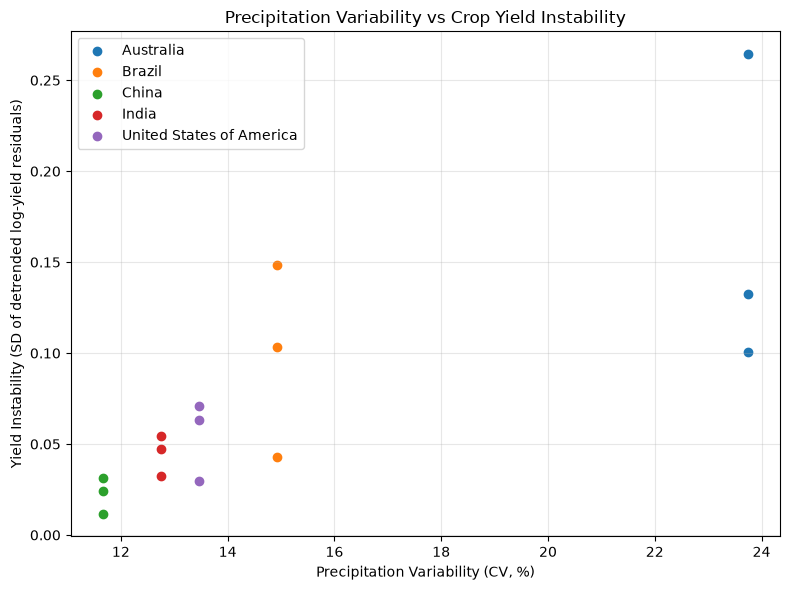

In [19]:
# Exploratory plot: precipitation variability vs yield instability

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for country in merged_variability["country"].unique():
    country_data = merged_variability[
        merged_variability["country"] == country
    ]

    plt.scatter(
        country_data["precipitation_CV_percent"],
        country_data["yield_instability_SD"],
        label=country
    )

plt.xlabel("Precipitation Variability (CV, %)")
plt.ylabel("Yield Instability (SD of detrended log-yield residuals)")
plt.title("Precipitation Variability vs Crop Yield Instability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

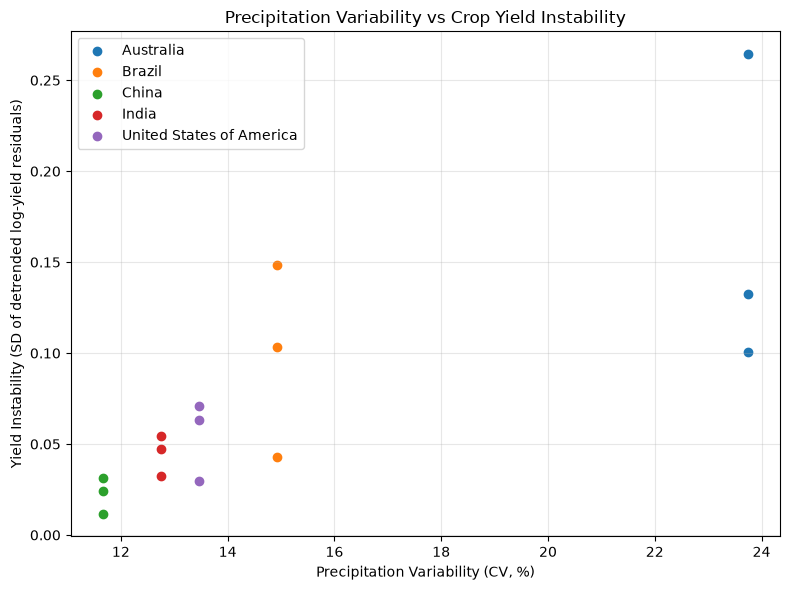

Plot saved successfully.
Path: ../figures/precipitation_variability_vs_yield_instability.png


In [20]:
# Save precipitation variability vs yield instability plot

plot_output_path = "../figures/precipitation_variability_vs_yield_instability.png"

plt.figure(figsize=(8, 6))

for country in merged_variability["country"].unique():
    country_data = merged_variability[
        merged_variability["country"] == country
    ]

    plt.scatter(
        country_data["precipitation_CV_percent"],
        country_data["yield_instability_SD"],
        label=country
    )

plt.xlabel("Precipitation Variability (CV, %)")
plt.ylabel("Yield Instability (SD of detrended log-yield residuals)")
plt.title("Precipitation Variability vs Crop Yield Instability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(plot_output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Plot saved successfully.")
print("Path:", plot_output_path)

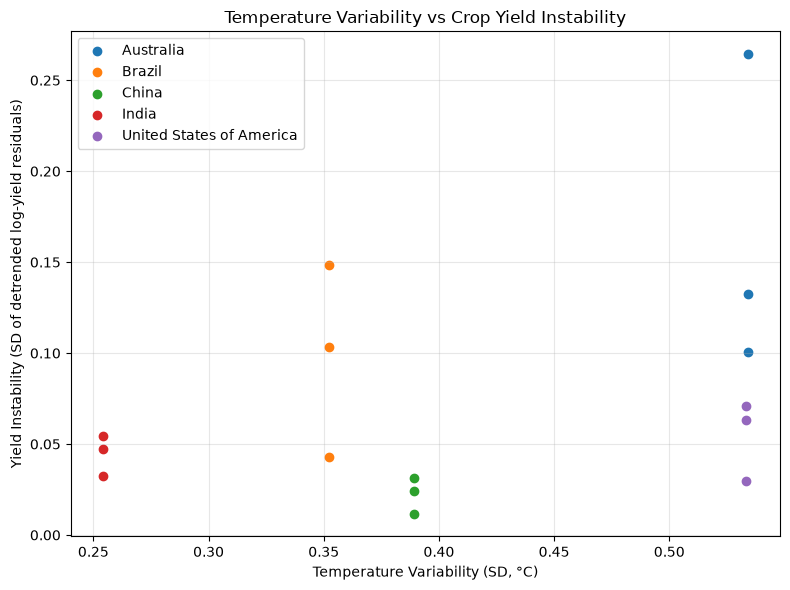

In [21]:
# Exploratory plot: temperature variability vs yield instability

plt.figure(figsize=(8, 6))

for country in merged_variability["country"].unique():
    country_data = merged_variability[
        merged_variability["country"] == country
    ]

    plt.scatter(
        country_data["temperature_SD_C"],
        country_data["yield_instability_SD"],
        label=country
    )

plt.xlabel("Temperature Variability (SD, °C)")
plt.ylabel("Yield Instability (SD of detrended log-yield residuals)")
plt.title("Temperature Variability vs Crop Yield Instability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

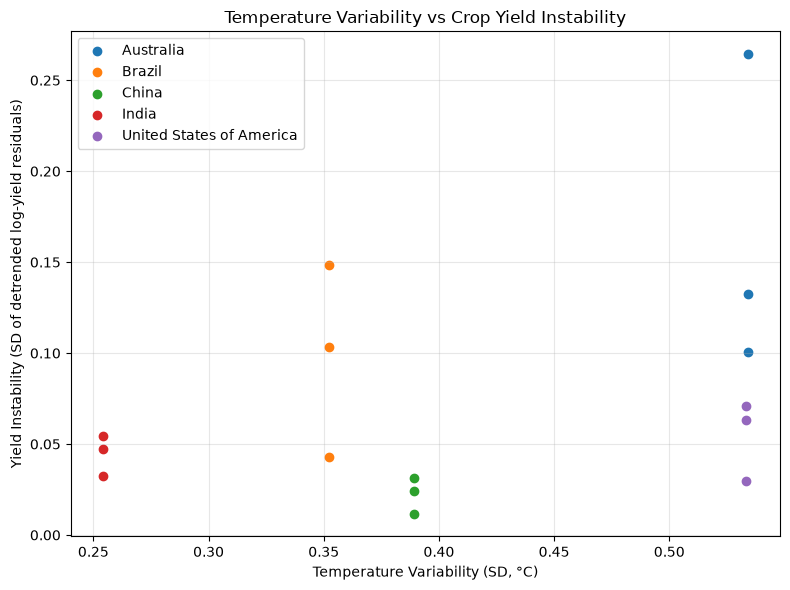

Plot saved successfully.
Path: ../figures/temperature_variability_vs_yield_instability.png


In [22]:
# Save temperature variability vs yield instability plot

plot_output_path = "../figures/temperature_variability_vs_yield_instability.png"

plt.figure(figsize=(8, 6))

for country in merged_variability["country"].unique():
    country_data = merged_variability[
        merged_variability["country"] == country
    ]

    plt.scatter(
        country_data["temperature_SD_C"],
        country_data["yield_instability_SD"],
        label=country
    )

plt.xlabel("Temperature Variability (SD, °C)")
plt.ylabel("Yield Instability (SD of detrended log-yield residuals)")
plt.title("Temperature Variability vs Crop Yield Instability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(plot_output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Plot saved successfully.")
print("Path:", plot_output_path)

In [23]:
# Calculate simple correlations between climate variability
# and crop yield instability

correlation_precipitation = merged_variability[
    "precipitation_CV_percent"
].corr(
    merged_variability["yield_instability_SD"]
)

correlation_temperature = merged_variability[
    "temperature_SD_C"
].corr(
    merged_variability["yield_instability_SD"]
)

print("Correlation results")
print("-------------------")

print(
    "Precipitation variability vs yield instability:",
    round(correlation_precipitation, 3)
)

print(
    "Temperature variability vs yield instability:",
    round(correlation_temperature, 3)
)

Correlation results
-------------------
Precipitation variability vs yield instability: 0.769
Temperature variability vs yield instability: 0.382


In [24]:
# Save exploratory correlation results

correlation_results = pd.DataFrame({
    "climate_variable": [
        "Precipitation variability",
        "Temperature variability"
    ],
    "yield_instability_measure": [
        "SD of detrended log-yield residuals",
        "SD of detrended log-yield residuals"
    ],
    "correlation": [
        correlation_precipitation,
        correlation_temperature
    ]
})

correlation_output_path = "../data/processed/exploratory_correlations.csv"

correlation_results.to_csv(
    correlation_output_path,
    index=False
)

print("Correlation results saved successfully.")
print("Path:", correlation_output_path)
print(correlation_results)

Correlation results saved successfully.
Path: ../data/processed/exploratory_correlations.csv
            climate_variable            yield_instability_measure  correlation
0  Precipitation variability  SD of detrended log-yield residuals     0.768733
1    Temperature variability  SD of detrended log-yield residuals     0.382311


In [25]:
import rasterio
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

# Paths
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"
era5_path = "../data/raw/era5_india/data_stream-moda.nc"

chirps_paths = {
    2021: "../data/raw/chirps_india/chirps-v2.0.2021.tif",
    2022: "../data/raw/chirps_india/chirps-v2.0.2022.tif",
    2023: "../data/raw/chirps_india/chirps-v2.0.2023.tif"
}

# Load India boundary
countries = gpd.read_file(boundary_path)
india = countries[countries["ADMIN"] == "India"].geometry.iloc[0]


# ---------------------------------------------------------
# CHIRPS India annual precipitation
# ---------------------------------------------------------

def calculate_chirps_india(path):
    with rasterio.open(path) as src:
        rainfall = src.read(1)
        transform = src.transform

        rows, cols = np.indices(rainfall.shape)

        lon = transform.c + (cols + 0.5) * transform.a
        lat = transform.f + (rows + 0.5) * transform.e

        india_mask = contains_xy(india, lon, lat)

        values = rainfall[india_mask]

        # Remove invalid/no-data values if present
        values = values[np.isfinite(values)]

        # Latitude-weighted mean
        weights = np.cos(np.deg2rad(lat[india_mask]))

        weighted_mean = np.sum(values * weights) / np.sum(weights)

        return weighted_mean


chirps_results = []

for year, path in chirps_paths.items():
    rainfall = calculate_chirps_india(path)

    chirps_results.append({
        "year": year,
        "CHIRPS_precipitation_mm": rainfall
    })

chirps_df = pd.DataFrame(chirps_results)


# ---------------------------------------------------------
# ERA5 India annual precipitation
# ---------------------------------------------------------

import xarray as xr

ds = xr.open_dataset(era5_path)

lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

india_mask = contains_xy(india, lon, lat)

tp = ds["tp"].where(india_mask)

weights = np.cos(np.deg2rad(ds.latitude))

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

days = ds["valid_time"].dt.days_in_month

monthly_rainfall_mm = monthly_tp * 1000 * days

era5_df = pd.DataFrame({
    "date": pd.to_datetime(ds["valid_time"].values),
    "ERA5_precipitation_mm": monthly_rainfall_mm.values
})

era5_df["year"] = era5_df["date"].dt.year

era5_annual = (
    era5_df
    .groupby("year")["ERA5_precipitation_mm"]
    .sum()
    .reset_index()
)

era5_annual = era5_annual[
    era5_annual["year"].isin([2021, 2022, 2023])
]


# ---------------------------------------------------------
# Compare
# ---------------------------------------------------------

comparison = pd.merge(
    era5_annual,
    chirps_df,
    on="year"
)

comparison["difference_mm"] = (
    comparison["ERA5_precipitation_mm"]
    - comparison["CHIRPS_precipitation_mm"]
)

comparison["ERA5_CHIRPS_ratio"] = (
    comparison["ERA5_precipitation_mm"]
    / comparison["CHIRPS_precipitation_mm"]
)

print("India precipitation: ERA5 vs CHIRPS")
print("------------------------------------")
print(comparison.to_string(index=False))

ds.close()

India precipitation: ERA5 vs CHIRPS
------------------------------------
 year  ERA5_precipitation_mm  CHIRPS_precipitation_mm  difference_mm  ERA5_CHIRPS_ratio
 2021            1298.552714              1269.509063      29.043651           1.022878
 2022            1181.258564              1280.868780     -99.610215           0.922232
 2023             651.514299              1094.751932    -443.237633           0.595125


In [26]:
import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

# Paths
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"
era5_usa_path = "../data/raw/era5_usa/data_stream-moda.nc"

# Load USA boundary
countries = gpd.read_file(boundary_path)

usa = countries[
    countries["ADMIN"] == "United States of America"
].geometry.iloc[0]

# Open ERA5 USA
ds = xr.open_dataset(era5_usa_path)

# Create grid
lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

# USA mask
usa_mask = contains_xy(usa, lon, lat)

# Extract precipitation
tp = ds["tp"].where(usa_mask)

# Latitude weighting
weights = np.cos(np.deg2rad(ds.latitude))

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# Convert ERA5 precipitation to mm/month
days = ds["valid_time"].dt.days_in_month

monthly_rainfall_mm = monthly_tp * 1000 * days

# Create dataframe
usa_df = pd.DataFrame({
    "date": pd.to_datetime(ds["valid_time"].values),
    "precipitation_mm": monthly_rainfall_mm.values
})

usa_df["year"] = usa_df["date"].dt.year

# Annual precipitation
usa_annual = (
    usa_df
    .groupby("year")["precipitation_mm"]
    .sum()
    .reset_index()
)

# Show recent years
print("USA ERA5 annual precipitation")
print("-----------------------------")
print(
    usa_annual[
        usa_annual["year"].between(2018, 2023)
    ].to_string(index=False)
)

ds.close()

USA ERA5 annual precipitation
-----------------------------
 year  precipitation_mm
 2018        916.686994
 2019        927.304706
 2020        789.631812
 2021        811.931607
 2022        643.855048
 2023        383.212168


In [27]:
# Check recent precipitation values across all five countries

recent_precip = climate_annual_all[
    climate_annual_all["year"].between(2020, 2023)
].copy()

recent_pivot = recent_precip.pivot(
    index="year",
    columns="country",
    values="precipitation_mm"
)

print("ERA5 annual precipitation: 2020–2023")
print("--------------------------------------")
print(recent_pivot.to_string())

print("\n2023 / 2022 precipitation ratio:")
print("----------------------------------")

ratio_2023_2022 = (
    recent_pivot.loc[2023] /
    recent_pivot.loc[2022]
)

print(ratio_2023_2022.to_string())

ERA5 annual precipitation: 2020–2023
--------------------------------------
country   Australia       Brazil       China        India  United States of America
year                                                                               
2020     465.412441  1667.129971  828.931246  1390.425356                789.631812
2021     472.628751  1771.026369  819.649790  1298.552714                811.931607
2022     451.814522  1404.999415  690.431124  1181.258564                643.855048
2023     241.260131   649.341225  409.280951   651.514299                383.212168

2023 / 2022 precipitation ratio:
----------------------------------
country
Australia                   0.533980
Brazil                      0.462165
China                       0.592790
India                       0.551542
United States of America    0.595184


In [28]:
import xarray as xr
import pandas as pd

era5_india_path = "../data/raw/era5_india/data_stream-moda.nc"

ds = xr.open_dataset(era5_india_path)

print("ERA5 time range:")
print(ds.valid_time.min().values, "to", ds.valid_time.max().values)

print("\nERA5 dimensions:")
print(ds.dims)

print("\nERA5 precipitation variable:")
print(ds["tp"])

print("\n2022 monthly mean tp values:")
print(
    ds["tp"]
    .sel(valid_time="2022")
    .mean(dim=("latitude", "longitude"))
    .values
)

print("\n2023 monthly mean tp values:")
print(
    ds["tp"]
    .sel(valid_time="2023")
    .mean(dim=("latitude", "longitude"))
    .values
)

print("\nExperiment version:")
print(ds["tp"].coords.get("expver", "No expver coordinate"))

ds.close()

ERA5 time range:
2000-01-01T00:00:00.000000000 to 2023-12-01T00:00:00.000000000

ERA5 dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 288, 'latitude': 311, 'longitude': 296})

ERA5 precipitation variable:
<xarray.DataArray 'tp' (valid_time: 288, latitude: 311, longitude: 296)> Size: 106MB
[26512128 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 2000-01-01 ... 2023-12-01
    expver      (valid_time) <U4 5kB ...
  * latitude    (latitude) float64 2kB 37.5 37.4 37.3 37.2 ... 6.8 6.7 6.6 6.5
  * longitude   (longitude) float64 2kB 68.0 68.1 68.2 68.3 ... 97.3 97.4 97.5
    number      int64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      92056
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...       

In [29]:
import xarray as xr
import numpy as np

era5_india_path = "../data/raw/era5_india/data_stream-moda.nc"

ds = xr.open_dataset(era5_india_path)

# Spatial mean over India grid
mean_tp = ds["tp"].mean(dim=("latitude", "longitude"))

print("EXPVER values:")
print(ds["expver"].values)

print("\n2022 monthly tp:")
print(
    mean_tp
    .sel(valid_time=slice("2022-01-01", "2022-12-01"))
    .values
)

print("\n2023 monthly tp:")
print(
    mean_tp
    .sel(valid_time=slice("2023-01-01", "2023-12-01"))
    .values
)

print("\n2022 mean tp:")
print(
    mean_tp
    .sel(valid_time=slice("2022-01-01", "2022-12-01"))
    .mean()
    .values
)

print("\n2023 mean tp:")
print(
    mean_tp
    .sel(valid_time=slice("2023-01-01", "2023-12-01"))
    .mean()
    .values
)

ds.close()

EXPVER values:
['0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001'
 '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001' '0001

In [30]:
import xarray as xr
import pandas as pd

# ---------------------------------------------------------
# ERA5 files
# ---------------------------------------------------------

era5_paths = {
    "India": "../data/raw/era5_india/data_stream-moda.nc",
    "China": "../data/raw/era5_china/data_stream-moda.nc",
    "United States": "../data/raw/era5_usa/data_stream-moda.nc",
    "Brazil": "../data/raw/era5_brazil/data_stream-moda.nc",
    "Australia": "../data/raw/era5_australia/data_stream-moda.nc"
}


# ---------------------------------------------------------
# Expected bounding boxes
# These are the areas we requested from ERA5
# ---------------------------------------------------------

expected_bounds = {
    "India": {
        "north": 37.5,
        "south": 6.5,
        "west": 68.0,
        "east": 97.5
    },

    "China": {
        "north": 53.6,
        "south": 18.2,
        "west": 73.5,
        "east": 134.8
    },

    "United States": {
        "north": 49.4,
        "south": 24.4,
        "west": -124.8,
        "east": -66.9
    },

    "Brazil": {
        "north": 5.3,
        "south": -33.8,
        "west": -74.0,
        "east": -34.8
    },

    "Australia": {
        "north": -10.7,
        "south": -43.7,
        "west": 113.3,
        "east": 153.6
    }
}


# ---------------------------------------------------------
# Inspect every file
# ---------------------------------------------------------

results = []

for country, path in era5_paths.items():

    ds = xr.open_dataset(path)

    actual_north = float(ds.latitude.max())
    actual_south = float(ds.latitude.min())
    actual_west = float(ds.longitude.min())
    actual_east = float(ds.longitude.max())

    expected = expected_bounds[country]

    results.append({
        "country": country,

        "actual_south": actual_south,
        "actual_north": actual_north,
        "actual_west": actual_west,
        "actual_east": actual_east,

        "expected_south": expected["south"],
        "expected_north": expected["north"],
        "expected_west": expected["west"],
        "expected_east": expected["east"],

        "lat_points": len(ds.latitude),
        "lon_points": len(ds.longitude)
    })

    ds.close()


# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------

check = pd.DataFrame(results)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("ERA5 COUNTRY FILE GEOGRAPHIC CHECK")
print("==================================")
print(check.to_string(index=False))

ERA5 COUNTRY FILE GEOGRAPHIC CHECK
      country  actual_south  actual_north  actual_west  actual_east  expected_south  expected_north  expected_west  expected_east  lat_points  lon_points
        India           6.5          37.5         68.0         97.5             6.5            37.5           68.0           97.5         311         296
        China          18.2          53.6         73.5        134.8            18.2            53.6           73.5          134.8         355         614
United States          24.4          49.4       -124.8        -66.9            24.4            49.4         -124.8          -66.9         251         580
       Brazil         -33.8           5.3        -74.0        -34.8           -33.8             5.3          -74.0          -34.8         392         393
    Australia         -43.7         -10.7        113.3        153.6           -43.7           -10.7          113.3          153.6         331         404


In [31]:
# Check monthly ERA5 precipitation for 2022 vs 2023
# This helps us identify whether the 2023 drop is systematic.

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"
countries = gpd.read_file(boundary_path)

era5_paths = {
    "Australia": "../data/raw/era5_australia/data_stream-moda.nc",
    "Brazil": "../data/raw/era5_brazil/data_stream-moda.nc",
    "China": "../data/raw/era5_china/data_stream-moda.nc",
    "India": "../data/raw/era5_india/data_stream-moda.nc",
    "United States of America": "../data/raw/era5_usa/data_stream-moda.nc"
}

def get_monthly_precipitation(nc_path, country_name):

    ds = xr.open_dataset(nc_path)

    country = countries[
        countries["ADMIN"] == country_name
    ].geometry.iloc[0]

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    country_mask = contains_xy(country, lon, lat)

    tp = ds["tp"].where(country_mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    # Convert ERA5-Land precipitation from metres
    # to mm/month
    days = ds["valid_time"].dt.days_in_month

    monthly_rainfall_mm = (
        monthly_tp * 1000 * days
    )

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": monthly_rainfall_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


# Check all five countries
for country, path in era5_paths.items():

    df = get_monthly_precipitation(
        path,
        country
    )

    comparison = df[
        df["year"].isin([2022, 2023])
    ].pivot(
        index="month",
        columns="year",
        values="precipitation_mm"
    )

    comparison["2023_2022_ratio"] = (
        comparison[2023] /
        comparison[2022]
    )

    print("\n" + "=" * 70)
    print(country)
    print("=" * 70)

    print(
        comparison.round(2).to_string()
    )


Australia
year     2022   2023  2023_2022_ratio
month                                
1      105.62  62.13             0.59
2       47.29  41.88             0.89
3       36.41  31.42             0.86
4       34.97  19.21             0.55
5       47.39   4.32             0.09
6       17.74  14.05             0.79
7       19.66   9.35             0.48
8       22.65   4.93             0.22
9       19.63   2.42             0.12
10      33.07   4.24             0.13
11      28.19  22.64             0.80
12      39.21  24.66             0.63

Brazil
year     2022    2023  2023_2022_ratio
month                                 
1      221.86  105.36             0.47
2      213.36   94.25             0.44
3      255.62  107.74             0.42
4      168.38   78.84             0.47
5      119.32   52.51             0.44
6       79.91   26.19             0.33
7       47.85   17.24             0.36
8       46.09   13.83             0.30
9       22.75   16.68             0.73
10      48.20   27.2

In [32]:
# Final diagnostic:
# Compare 2023 monthly precipitation with the 2000-2022 monthly average

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"
countries = gpd.read_file(boundary_path)

era5_paths = {
    "Australia": "../data/raw/era5_australia/data_stream-moda.nc",
    "Brazil": "../data/raw/era5_brazil/data_stream-moda.nc",
    "China": "../data/raw/era5_china/data_stream-moda.nc",
    "India": "../data/raw/era5_india/data_stream-moda.nc",
    "United States of America": "../data/raw/era5_usa/data_stream-moda.nc"
}

def get_monthly_precipitation(nc_path, country_name):

    ds = xr.open_dataset(nc_path)

    country = countries[
        countries["ADMIN"] == country_name
    ].geometry.iloc[0]

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    country_mask = contains_xy(country, lon, lat)

    tp = ds["tp"].where(country_mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    monthly_rainfall_mm = (
        monthly_tp * 1000 * days
    )

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": monthly_rainfall_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


diagnostic_results = []

for country, path in era5_paths.items():

    df = get_monthly_precipitation(
        path,
        country
    )

    # Average precipitation for each month
    # across 2000-2022
    monthly_average = (
        df[df["year"] <= 2022]
        .groupby("month")["precipitation_mm"]
        .mean()
    )

    # 2023 precipitation
    precipitation_2023 = (
        df[df["year"] == 2023]
        .set_index("month")["precipitation_mm"]
    )

    ratio = precipitation_2023 / monthly_average

    diagnostic_results.append({
        "country": country,
        "mean_2023_to_2000_2022_ratio": ratio.mean(),
        "minimum_monthly_ratio": ratio.min(),
        "maximum_monthly_ratio": ratio.max(),
        "months_below_50_percent": (ratio < 0.50).sum()
    })

diagnostic_results = pd.DataFrame(
    diagnostic_results
)

print("2023 PRECIPITATION DIAGNOSTIC")
print("=" * 70)

print(
    diagnostic_results.round(3).to_string(index=False)
)

2023 PRECIPITATION DIAGNOSTIC
                 country  mean_2023_to_2000_2022_ratio  minimum_monthly_ratio  maximum_monthly_ratio  months_below_50_percent
               Australia                         0.488                  0.164                  0.809                        5
                  Brazil                         0.344                  0.238                  0.453                       12
                   China                         0.503                  0.318                  0.594                        5
                   India                         0.550                  0.249                  0.892                        5
United States of America                         0.486                  0.363                  0.724                        7


In [1]:
# ============================================================
# CHECK CORRECTED INDIA 2023 ERA5-LAND PRECIPITATION
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

new_path = "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

# ------------------------------------------------------------
# Load corrected ERA5-Land file
# ------------------------------------------------------------

ds = xr.open_dataset(new_path)

print("DATASET:")
print(ds)

# ------------------------------------------------------------
# Identify time coordinate
# ------------------------------------------------------------

if "valid_time" in ds.coords:
    time_coord = "valid_time"
elif "time" in ds.coords:
    time_coord = "time"
else:
    raise ValueError("Could not find time coordinate.")

print("\nTime coordinate:", time_coord)
print("Time range:", ds[time_coord].values[0], "to", ds[time_coord].values[-1])

# ------------------------------------------------------------
# Load India boundary
# ------------------------------------------------------------

countries = gpd.read_file(boundary_path)

india = countries[
    countries["ADMIN"] == "India"
].geometry.iloc[0]

# ------------------------------------------------------------
# Create spatial grid
# ------------------------------------------------------------

lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

india_mask = contains_xy(
    india,
    lon,
    lat
)

# ------------------------------------------------------------
# Extract precipitation
# ------------------------------------------------------------

tp = ds["tp"].where(india_mask)

# Area weighting
weights = np.cos(
    np.deg2rad(ds.latitude)
)

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# ------------------------------------------------------------
# Convert precipitation to mm/month
# ------------------------------------------------------------

days = ds[time_coord].dt.days_in_month

monthly_precipitation_mm = (
    monthly_tp * 1000 * days
)

# ------------------------------------------------------------
# Create table
# ------------------------------------------------------------

corrected_2023 = pd.DataFrame({
    "date": pd.to_datetime(ds[time_coord].values),
    "precipitation_mm": monthly_precipitation_mm.values
})

corrected_2023["month"] = corrected_2023["date"].dt.month

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nCORRECTED INDIA 2023 MONTHLY PRECIPITATION")
print("=" * 60)

print(
    corrected_2023[
        ["month", "precipitation_mm"]
    ].round(2).to_string(index=False)
)

total_2023 = corrected_2023["precipitation_mm"].sum()

print("\nCorrected India 2023 precipitation:")
print(f"{total_2023:.2f} mm")

# ------------------------------------------------------------
# Compare with old value
# ------------------------------------------------------------

old_value = 651.514299

print("\nOLD ERA5 VALUE:")
print(f"{old_value:.2f} mm")

print("\nDIFFERENCE:")
print(f"{total_2023 - old_value:.2f} mm")

print("\nRATIO (corrected / old):")
print(f"{total_2023 / old_value:.3f}")

ds.close()

DATASET:
<xarray.Dataset> Size: 4MB
Dimensions:     (valid_time: 12, latitude: 311, longitude: 296)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 96B 2023-01-02 ... 2023-12-02
    expver      (valid_time) <U4 192B ...
  * latitude    (latitude) float64 2kB 37.5 37.4 37.3 37.2 ... 6.8 6.7 6.6 6.5
  * longitude   (longitude) float64 2kB 68.0 68.1 68.2 68.3 ... 97.3 97.4 97.5
    number      int64 8B ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 4MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-06T18:37 GRIB to CDM+CF via cfgrib-0.9.1...

Time coordinate: valid_time
Time range: 2023-01-02T00:00:00.000000000 to 2023-12-02T00:00:00.000000000

CORRECTED INDIA 2023 MONTHLY PRECIPITATION


In [2]:
print("\nTP METADATA")
print("=" * 60)

for key, value in ds["tp"].attrs.items():
    print(f"{key}: {value}")


TP METADATA
GRIB_paramId: 228
GRIB_dataType: fc
GRIB_numberOfPoints: 92056
GRIB_typeOfLevel: surface
GRIB_stepUnits: 1
GRIB_gridType: regular_ll
GRIB_uvRelativeToGrid: 0
GRIB_NV: 0
GRIB_Nx: 296
GRIB_Ny: 311
GRIB_cfName: unknown
GRIB_cfVarName: tp
GRIB_gridDefinitionDescription: Latitude/Longitude Grid
GRIB_iDirectionIncrementInDegrees: 0.1
GRIB_iScansNegatively: 0
GRIB_jDirectionIncrementInDegrees: 0.1
GRIB_jPointsAreConsecutive: 0
GRIB_jScansPositively: 0
GRIB_latitudeOfFirstGridPointInDegrees: 37.5
GRIB_latitudeOfLastGridPointInDegrees: 6.5
GRIB_longitudeOfFirstGridPointInDegrees: 68.0
GRIB_longitudeOfLastGridPointInDegrees: 97.5
GRIB_missingValue: 3.4028234663852886e+38
GRIB_name: Total precipitation
GRIB_shortName: tp
GRIB_totalNumber: 0
GRIB_units: m
long_name: Total precipitation
units: m
standard_name: unknown
GRIB_surface: 0.0


In [3]:
import xarray as xr

test_ds = xr.open_dataset(
    "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
)

print("TP ATTRIBUTES")
print("=" * 60)

for key, value in test_ds["tp"].attrs.items():
    print(f"{key}: {value}")

test_ds.close()

TP ATTRIBUTES
GRIB_paramId: 228
GRIB_dataType: fc
GRIB_numberOfPoints: 92056
GRIB_typeOfLevel: surface
GRIB_stepUnits: 1
GRIB_gridType: regular_ll
GRIB_uvRelativeToGrid: 0
GRIB_NV: 0
GRIB_Nx: 296
GRIB_Ny: 311
GRIB_cfName: unknown
GRIB_cfVarName: tp
GRIB_gridDefinitionDescription: Latitude/Longitude Grid
GRIB_iDirectionIncrementInDegrees: 0.1
GRIB_iScansNegatively: 0
GRIB_jDirectionIncrementInDegrees: 0.1
GRIB_jPointsAreConsecutive: 0
GRIB_jScansPositively: 0
GRIB_latitudeOfFirstGridPointInDegrees: 37.5
GRIB_latitudeOfLastGridPointInDegrees: 6.5
GRIB_longitudeOfFirstGridPointInDegrees: 68.0
GRIB_longitudeOfLastGridPointInDegrees: 97.5
GRIB_missingValue: 3.4028234663852886e+38
GRIB_name: Total precipitation
GRIB_shortName: tp
GRIB_totalNumber: 0
GRIB_units: m
long_name: Total precipitation
units: m
standard_name: unknown
GRIB_surface: 0.0


In [4]:
import xarray as xr

ds_check = xr.open_dataset(
    "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
)

print("Forecast step:")
print(ds_check["tp"].attrs.get("GRIB_step"))

print("\nAll TP attributes containing 'step':")
for key, value in ds_check["tp"].attrs.items():
    if "step" in key.lower():
        print(key, ":", value)

ds_check.close()

Forecast step:
None

All TP attributes containing 'step':
GRIB_stepUnits : 1


In [5]:
import xarray as xr
import numpy as np

ds = xr.open_dataset(
    "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
)

tp = ds["tp"]

print("RAW TP STATISTICS")
print("=" * 50)
print("Mean:", float(tp.mean()))
print("Min :", float(tp.min()))
print("Max :", float(tp.max()))

print("\nIf treated as m per 24 hours:")
print("Annual precipitation estimate:",
      float(tp.mean()) * 1000 * 365)

ds.close()

RAW TP STATISTICS
Mean: 0.002883469918742776
Min : 7.049690111671225e-07
Max : 0.06157808378338814

If treated as m per 24 hours:
Annual precipitation estimate: 1052.4665203411132


In [6]:
# ============================================================
# EXACT CORRECTED INDIA 2023 PRECIPITATION
# ERA5-Land monthly averaged by hour of day
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

new_path = "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

ds = xr.open_dataset(new_path)

# India boundary
countries = gpd.read_file(boundary_path)
india = countries[countries["ADMIN"] == "India"].geometry.iloc[0]

# Grid
lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

india_mask = contains_xy(india, lon, lat)

# India precipitation
tp = ds["tp"].where(india_mask)

# Area weighting
weights = np.cos(np.deg2rad(ds.latitude))

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# IMPORTANT:
# mnth product = accumulation per forecast-step hours.
# At 00 UTC this represents the preceding 24-hour accumulation.
monthly_precip_mm = monthly_tp * 1000

# Table
corrected = pd.DataFrame({
    "date": pd.to_datetime(ds["valid_time"].values),
    "precipitation_mm": monthly_precip_mm.values
})

corrected["month"] = corrected["date"].dt.month

print("CORRECTED INDIA 2023")
print("=" * 60)

print(
    corrected[
        ["month", "precipitation_mm"]
    ].round(2).to_string(index=False)
)

annual_total = corrected["precipitation_mm"].sum()

print("\nAnnual precipitation:")
print(f"{annual_total:.2f} mm")

print("\nCHIRPS 2023:")
print("1094.75 mm")

print("\nERA5 corrected / CHIRPS:")
print(f"{annual_total / 1094.751932:.3f}")

ds.close()

CORRECTED INDIA 2023
 month  precipitation_mm
     1              0.53
     2              0.43
     3              1.51
     4              1.49
     5              2.15
     6              5.62
     7             10.92
     8              5.89
     9              7.08
    10              1.70
    11              1.58
    12              0.95

Annual precipitation:
39.87 mm

CHIRPS 2023:
1094.75 mm

ERA5 corrected / CHIRPS:
0.036


In [7]:
import xarray as xr
import pandas as pd

ds = xr.open_dataset(
    "../data/raw/era5_corrected/india_2023/data_stream-mnth.nc"
)

tp = ds["tp"]

print("Monthly mean TP:")
print(tp.mean(dim=("latitude", "longitude")).values)

print("\nDays in each month:")
print(ds["valid_time"].dt.days_in_month.values)

print("\nSum of spatial mean TP:")
print(float(tp.mean(dim=("latitude", "longitude")).sum()))

print("\nSum × 1000:")
print(float(tp.mean(dim=("latitude", "longitude")).sum()) * 1000)

print("\nSum × 1000 × days:")
print(
    float(
        (
            tp.mean(dim=("latitude", "longitude"))
            * 1000
            * ds["valid_time"].dt.days_in_month
        ).sum()
    )
)

ds.close()

Monthly mean TP:
[0.00055937 0.00063777 0.00140586 0.00142709 0.00237501 0.004973
 0.00818631 0.00585949 0.00523863 0.00199515 0.00121492 0.00072902]

Days in each month:
[31 28 31 30 31 30 31 31 30 31 30 31]

Sum of spatial mean TP:
0.034601639956235886

Sum × 1000:
34.601639956235886

Sum × 1000 × days:
1057.883936047554


In [8]:
# ============================================================
# CHECK CORRECTED INDIA 2022 PRECIPITATION
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

path_2022 = "../data/raw/era5_corrected/india_2022/data_stream-mnth.nc"
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

ds = xr.open_dataset(path_2022)

# India boundary
countries = gpd.read_file(boundary_path)
india = countries[countries["ADMIN"] == "India"].geometry.iloc[0]

# Grid
lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

india_mask = contains_xy(india, lon, lat)

# Precipitation
tp = ds["tp"].where(india_mask)

# Area weighting
weights = np.cos(np.deg2rad(ds.latitude))

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# mnth product gives mean daily accumulation
# Convert m/day -> mm/day
monthly_mm_per_day = monthly_tp * 1000

# Number of days in each month
days = ds["valid_time"].dt.days_in_month

# Convert to total mm/month
monthly_precip_mm = monthly_mm_per_day * days

# Create table
corrected_2022 = pd.DataFrame({
    "date": pd.to_datetime(ds["valid_time"].values),
    "precipitation_mm": monthly_precip_mm.values
})

corrected_2022["month"] = corrected_2022["date"].dt.month

print("CORRECTED INDIA 2022")
print("=" * 60)

print(
    corrected_2022[
        ["month", "precipitation_mm"]
    ].round(2).to_string(index=False)
)

print("\nAnnual precipitation:")
print(
    f"{corrected_2022['precipitation_mm'].sum():.2f} mm"
)

print("\nSeptember-December 2022:")
print(
    corrected_2022[
        corrected_2022["month"] >= 9
    ][["month", "precipitation_mm"]]
    .round(2)
    .to_string(index=False)
)

ds.close()

CORRECTED INDIA 2022
 month  precipitation_mm
     1             41.46
     2             22.85
     3             11.93
     4             44.58
     5             83.46
     6            160.73
     7            344.81
     8            277.77
     9            201.86
    10            119.28
    11             19.75
    12             18.99

Annual precipitation:
1347.46 mm

September-December 2022:
 month  precipitation_mm
     9            201.86
    10            119.28
    11             19.75
    12             18.99


In [9]:
# ============================================================
# VALIDATE CORRECTED INDIA 2022 AGAINST ORIGINAL ERA5
# January-August should agree
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_india/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/india_2022/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)
india = countries[countries["ADMIN"] == "India"].geometry.iloc[0]


def get_india_precip(path, product_type):
    
    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(india, lon, lat)

    tp = ds["tp"].where(mask)

    weights = np.cos(np.deg2rad(ds.latitude))

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    if product_type == "moda":
        # Original monthly averaged product
        precipitation_mm = monthly_tp * 1000 * days

    elif product_type == "mnth":
        # Corrected monthly averaged by hour-of-day product
        precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["month"] = df["date"].dt.month

    ds.close()

    return df


old = get_india_precip(old_path, "moda")
new = get_india_precip(new_path, "mnth")

comparison = pd.merge(
    old[old["month"] <= 8],
    new[new["month"] <= 8],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)

print("INDIA 2022 VALIDATION")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

INDIA 2022 VALIDATION
  date_old  precipitation_mm_old  month date_corrected  precipitation_mm_corrected  difference_mm  difference_percent
2000-01-01                 17.14      1     2022-01-02                       41.46          24.32              141.93
2000-02-01                 32.12      2     2022-02-02                       22.85          -9.27              -28.87
2000-03-01                 24.07      3     2022-03-02                       11.93         -12.15              -50.46
2000-04-01                 48.08      4     2022-04-02                       44.58          -3.50               -7.28
2000-05-01                101.56      5     2022-05-02                       83.46         -18.09              -17.81
2000-06-01                217.90      6     2022-06-02                      160.73         -57.18              -26.24
2000-07-01                273.33      7     2022-07-02                      344.81          71.48               26.15
2000-08-01                238.63  

/tmp/ipykernel_39642/1499287087.py:87: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  comparison.round(2).to_string(index=False)


In [10]:
# ============================================================
# CORRECT INDIA 2022 VALIDATION
# Compare ONLY Jan-Aug 2022
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_india/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/india_2022/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)
india = countries[countries["ADMIN"] == "India"].geometry.iloc[0]


def get_india_precip(path, product_type):

    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(india, lon, lat)

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    # Both products need m/day -> mm/month
    precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


# Load both datasets
old = get_india_precip(old_path, "moda")
new = get_india_precip(new_path, "mnth")


# IMPORTANT:
# Keep ONLY 2022 from the old dataset
old_2022 = old[
    (old["year"] == 2022) &
    (old["month"] <= 8)
].copy()

# Keep ONLY Jan-Aug 2022 from corrected dataset
new_2022 = new[
    (new["year"] == 2022) &
    (new["month"] <= 8)
].copy()


# Compare month-by-month
comparison = pd.merge(
    old_2022[["month", "precipitation_mm"]],
    new_2022[["month", "precipitation_mm"]],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)


print("INDIA 2022 VALIDATION — JANUARY TO AUGUST")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute difference:")
print(
    f"{comparison['difference_mm'].abs().mean():.2f} mm"
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

INDIA 2022 VALIDATION — JANUARY TO AUGUST
 month  precipitation_mm_old  precipitation_mm_corrected  difference_mm  difference_percent
     1                 41.46                       41.46            0.0                 0.0
     2                 22.85                       22.85            0.0                 0.0
     3                 11.93                       11.93            0.0                 0.0
     4                 44.58                       44.58            0.0                 0.0
     5                 83.46                       83.46            0.0                 0.0
     6                160.73                      160.73            0.0                 0.0
     7                344.81                      344.81            0.0                 0.0
     8                277.77                      277.77            0.0                 0.0

Mean absolute difference:
0.00 mm

Mean absolute percentage difference:
0.00%


In [11]:
# ============================================================
# CHINA 2022 VALIDATION — JANUARY TO AUGUST
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_china/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/china/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)

china = countries[
    countries["ADMIN"] == "China"
].geometry.iloc[0]


def get_china_precip(path):

    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(china, lon, lat)

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    # Convert m/day -> mm/month
    precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


old = get_china_precip(old_path)
new = get_china_precip(new_path)

# ONLY 2022 Jan-Aug
old_2022 = old[
    (old["year"] == 2022) &
    (old["month"] <= 8)
]

new_2022 = new[
    (new["year"] == 2022) &
    (new["month"] <= 8)
]

comparison = pd.merge(
    old_2022[["month", "precipitation_mm"]],
    new_2022[["month", "precipitation_mm"]],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)

print("CHINA 2022 VALIDATION — JANUARY TO AUGUST")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute difference:")
print(
    f"{comparison['difference_mm'].abs().mean():.2f} mm"
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

CHINA 2022 VALIDATION — JANUARY TO AUGUST
 month  precipitation_mm_old  precipitation_mm_corrected  difference_mm  difference_percent
     1                 25.97                       25.97            0.0                 0.0
     2                 31.58                       31.58            0.0                 0.0
     3                 48.45                       48.45            0.0                 0.0
     4                 58.17                       58.17            0.0                 0.0
     5                 92.81                       92.81            0.0                 0.0
     6                134.19                      134.19            0.0                 0.0
     7                112.12                      112.12            0.0                 0.0
     8                102.99                      102.99            0.0                 0.0

Mean absolute difference:
0.00 mm

Mean absolute percentage difference:
0.00%


In [12]:
# ============================================================
# CHINA — CORRECTED 2022 + 2023 PRECIPITATION
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

path = "../data/raw/era5_corrected/china/data_stream-mnth.nc"
boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

ds = xr.open_dataset(path)

# China boundary
countries = gpd.read_file(boundary_path)

china = countries[
    countries["ADMIN"] == "China"
].geometry.iloc[0]

# Grid
lon, lat = np.meshgrid(
    ds.longitude.values,
    ds.latitude.values
)

mask = contains_xy(
    china,
    lon,
    lat
)

# Precipitation
tp = ds["tp"].where(mask)

# Area weighting
weights = np.cos(
    np.deg2rad(ds.latitude)
)

monthly_tp = tp.weighted(weights).mean(
    dim=("latitude", "longitude")
)

# mnth = mean daily accumulation
days = ds["valid_time"].dt.days_in_month

monthly_precip_mm = (
    monthly_tp * 1000 * days
)

# Table
china_corrected = pd.DataFrame({
    "date": pd.to_datetime(ds["valid_time"].values),
    "precipitation_mm": monthly_precip_mm.values
})

china_corrected["year"] = china_corrected["date"].dt.year
china_corrected["month"] = china_corrected["date"].dt.month

print("CHINA CORRECTED PRECIPITATION")
print("=" * 70)

print(
    china_corrected.round(2).to_string(index=False)
)

print("\nANNUAL TOTALS")
print("=" * 70)

annual = (
    china_corrected
    .groupby("year")["precipitation_mm"]
    .sum()
)

print(annual.round(2))

print("\nSEP-DEC 2022")
print("=" * 70)

print(
    china_corrected[
        (china_corrected["year"] == 2022) &
        (china_corrected["month"] >= 9)
    ][["month", "precipitation_mm"]]
    .round(2)
    .to_string(index=False)
)

ds.close()

CHINA CORRECTED PRECIPITATION
      date  precipitation_mm  year  month
2022-01-02             25.97  2022      1
2022-02-02             31.58  2022      2
2022-03-02             48.45  2022      3
2022-04-02             58.17  2022      4
2022-05-02             92.81  2022      5
2022-06-02            134.19  2022      6
2022-07-02            112.12  2022      7
2022-08-02            102.99  2022      8
2022-09-02             66.00  2022      9
2022-10-02             44.35  2022     10
2022-11-02             35.86  2022     11
2022-12-02             11.34  2022     12
2023-01-02             13.16  2023      1
2023-02-02             23.18  2023      2
2023-03-02             35.47  2023      3
2023-04-02             61.69  2023      4
2023-05-02             76.03  2023      5
2023-06-02            103.76  2023      6
2023-07-02            134.62  2023      7
2023-08-02            131.04  2023      8
2023-09-02             85.53  2023      9
2023-10-02             46.03  2023     10
2023

/tmp/ipykernel_39642/2772964346.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  china_corrected.round(2).to_string(index=False)


In [13]:
print("CHINA CORRECTED ANNUAL PRECIPITATION")
print("=" * 50)

annual = (
    china_corrected
    .groupby("year")["precipitation_mm"]
    .sum()
)

for year, value in annual.items():
    print(f"{year}: {value:.2f} mm")

CHINA CORRECTED ANNUAL PRECIPITATION
2022: 763.83 mm
2023: 756.42 mm


In [14]:
# ============================================================
# USA 2022 VALIDATION — JANUARY TO AUGUST
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_usa/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/usa/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)

usa = countries[
    countries["ADMIN"] == "United States of America"
].geometry.iloc[0]


def get_usa_precip(path):

    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(usa, lon, lat)

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


old = get_usa_precip(old_path)
new = get_usa_precip(new_path)

# ONLY 2022 January-August
old_2022 = old[
    (old["year"] == 2022) &
    (old["month"] <= 8)
]

new_2022 = new[
    (new["year"] == 2022) &
    (new["month"] <= 8)
]

comparison = pd.merge(
    old_2022[["month", "precipitation_mm"]],
    new_2022[["month", "precipitation_mm"]],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)

print("USA 2022 VALIDATION — JANUARY TO AUGUST")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute difference:")
print(
    f"{comparison['difference_mm'].abs().mean():.2f} mm"
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

USA 2022 VALIDATION — JANUARY TO AUGUST
 month  precipitation_mm_old  precipitation_mm_corrected  difference_mm  difference_percent
     1                 46.80                       46.80            0.0                 0.0
     2                 50.66                       50.66            0.0                 0.0
     3                 66.18                       66.18            0.0                 0.0
     4                 77.52                       77.52            0.0                 0.0
     5                 86.86                       86.86            0.0                 0.0
     6                 57.37                       57.37            0.0                 0.0
     7                 65.85                       65.85            0.0                 0.0
     8                 75.43                       75.43            0.0                 0.0

Mean absolute difference:
0.00 mm

Mean absolute percentage difference:
0.00%


In [15]:
# ============================================================
# USA — CORRECTED 2022 + 2023 PRECIPITATION
# ============================================================

# We already have `new` from the previous cell.

usa_corrected = new.copy()

print("USA CORRECTED ANNUAL PRECIPITATION")
print("=" * 60)

annual_usa = (
    usa_corrected
    .groupby("year")["precipitation_mm"]
    .sum()
)

for year, value in annual_usa.items():
    print(f"{year}: {value:.2f} mm")

print("\nUSA SEP-DEC 2022")
print("=" * 60)

print(
    usa_corrected[
        (usa_corrected["year"] == 2022) &
        (usa_corrected["month"] >= 9)
    ][["month", "precipitation_mm"]]
    .round(2)
    .to_string(index=False)
)

USA CORRECTED ANNUAL PRECIPITATION
2022: 759.85 mm
2023: 776.22 mm

USA SEP-DEC 2022
 month  precipitation_mm
     9             48.00
    10             44.35
    11             65.56
    12             75.27


In [16]:
# ============================================================
# BRAZIL 2022 VALIDATION — JANUARY TO AUGUST
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_brazil/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/brazil/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)

brazil = countries[
    countries["ADMIN"] == "Brazil"
].geometry.iloc[0]


def get_brazil_precip(path):

    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(brazil, lon, lat)

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


old = get_brazil_precip(old_path)
new = get_brazil_precip(new_path)

# ONLY 2022 January-August
old_2022 = old[
    (old["year"] == 2022) &
    (old["month"] <= 8)
]

new_2022 = new[
    (new["year"] == 2022) &
    (new["month"] <= 8)
]

comparison = pd.merge(
    old_2022[["month", "precipitation_mm"]],
    new_2022[["month", "precipitation_mm"]],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)

print("BRAZIL 2022 VALIDATION — JANUARY TO AUGUST")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute difference:")
print(
    f"{comparison['difference_mm'].abs().mean():.2f} mm"
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

BRAZIL 2022 VALIDATION — JANUARY TO AUGUST
 month  precipitation_mm_old  precipitation_mm_corrected  difference_mm  difference_percent
     1                221.86                      221.86            0.0                 0.0
     2                213.36                      213.36            0.0                 0.0
     3                255.62                      255.62            0.0                 0.0
     4                168.38                      168.38            0.0                 0.0
     5                119.32                      119.32            0.0                 0.0
     6                 79.91                       79.91            0.0                 0.0
     7                 47.85                       47.85            0.0                 0.0
     8                 46.09                       46.09            0.0                 0.0

Mean absolute difference:
0.00 mm

Mean absolute percentage difference:
0.00%


In [17]:
# ============================================================
# BRAZIL — CORRECTED 2022 + 2023 PRECIPITATION
# ============================================================

brazil_corrected = new.copy()

print("BRAZIL CORRECTED ANNUAL PRECIPITATION")
print("=" * 60)

annual_brazil = (
    brazil_corrected
    .groupby("year")["precipitation_mm"]
    .sum()
)

for year, value in annual_brazil.items():
    print(f"{year}: {value:.2f} mm")

print("\nBRAZIL SEP-DEC 2022")
print("=" * 60)

print(
    brazil_corrected[
        (brazil_corrected["year"] == 2022) &
        (brazil_corrected["month"] >= 9)
    ][["month", "precipitation_mm"]]
    .round(2)
    .to_string(index=False)
)

BRAZIL CORRECTED ANNUAL PRECIPITATION
2022: 1698.61 mm
2023: 1428.31 mm

BRAZIL SEP-DEC 2022
 month  precipitation_mm
     9             50.35
    10            107.70
    11            162.58
    12            225.58


In [18]:
# ============================================================
# AUSTRALIA 2022 VALIDATION — JANUARY TO AUGUST
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy

boundary_path = "../data/raw/boundaries/ne_10m_admin_0_countries.shp"

old_path = "../data/raw/era5_australia/data_stream-moda.nc"
new_path = "../data/raw/era5_corrected/australia/data_stream-mnth.nc"

countries = gpd.read_file(boundary_path)

australia = countries[
    countries["ADMIN"] == "Australia"
].geometry.iloc[0]


def get_australia_precip(path):

    ds = xr.open_dataset(path)

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(
        australia,
        lon,
        lat
    )

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    precipitation_mm = monthly_tp * 1000 * days

    df = pd.DataFrame({
        "date": pd.to_datetime(ds["valid_time"].values),
        "precipitation_mm": precipitation_mm.values
    })

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    ds.close()

    return df


old = get_australia_precip(old_path)
new = get_australia_precip(new_path)

# ONLY 2022 January-August
old_2022 = old[
    (old["year"] == 2022) &
    (old["month"] <= 8)
]

new_2022 = new[
    (new["year"] == 2022) &
    (new["month"] <= 8)
]

comparison = pd.merge(
    old_2022[["month", "precipitation_mm"]],
    new_2022[["month", "precipitation_mm"]],
    on="month",
    suffixes=("_old", "_corrected")
)

comparison["difference_mm"] = (
    comparison["precipitation_mm_corrected"]
    - comparison["precipitation_mm_old"]
)

comparison["difference_percent"] = (
    comparison["difference_mm"]
    / comparison["precipitation_mm_old"]
    * 100
)

print("AUSTRALIA 2022 VALIDATION — JANUARY TO AUGUST")
print("=" * 70)

print(
    comparison.round(2).to_string(index=False)
)

print("\nMean absolute difference:")
print(
    f"{comparison['difference_mm'].abs().mean():.2f} mm"
)

print("\nMean absolute percentage difference:")
print(
    f"{comparison['difference_percent'].abs().mean():.2f}%"
)

AUSTRALIA 2022 VALIDATION — JANUARY TO AUGUST
 month  precipitation_mm_old  precipitation_mm_corrected  difference_mm  difference_percent
     1                105.62                      105.62            0.0                 0.0
     2                 47.29                       47.29            0.0                 0.0
     3                 36.41                       36.41            0.0                 0.0
     4                 34.97                       34.97            0.0                 0.0
     5                 47.39                       47.39            0.0                 0.0
     6                 17.74                       17.74            0.0                 0.0
     7                 19.66                       19.66            0.0                 0.0
     8                 22.65                       22.65            0.0                 0.0

Mean absolute difference:
0.00 mm

Mean absolute percentage difference:
0.00%


In [19]:
# ============================================================
# AUSTRALIA — CORRECTED 2022 + 2023 PRECIPITATION
# ============================================================

australia_corrected = new.copy()

print("AUSTRALIA CORRECTED ANNUAL PRECIPITATION")
print("=" * 60)

annual_australia = (
    australia_corrected
    .groupby("year")["precipitation_mm"]
    .sum()
)

for year, value in annual_australia.items():
    print(f"{year}: {value:.2f} mm")

print("\nAUSTRALIA SEP-DEC 2022")
print("=" * 60)

print(
    australia_corrected[
        (australia_corrected["year"] == 2022) &
        (australia_corrected["month"] >= 9)
    ][["month", "precipitation_mm"]]
    .round(2)
    .to_string(index=False)
)

AUSTRALIA CORRECTED ANNUAL PRECIPITATION
2022: 550.76 mm
2023: 432.51 mm

AUSTRALIA SEP-DEC 2022
 month  precipitation_mm
     9             36.21
    10             60.44
    11             50.11
    12             72.29


In [20]:
# ============================================================
# STEP 1 — BUILD CORRECTED MASTER CLIMATE DATASET
# ============================================================

import xarray as xr
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import contains_xy
from pathlib import Path

# ------------------------------------------------------------
# Create report-ready folders
# ------------------------------------------------------------

report_dir = Path("../results/report_ready")

tables_dir = report_dir / "tables"
figures_dir = report_dir / "figures"
notes_dir = report_dir / "notes"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
notes_dir.mkdir(parents=True, exist_ok=True)

print("Report folders created:")
print(report_dir)


# ------------------------------------------------------------
# Load existing climate dataset
# ------------------------------------------------------------

climate_monthly = pd.read_csv(
    "../data/processed/climate_monthly_all.csv"
)

print("\nExisting climate dataset:")
print(climate_monthly.shape)
print(climate_monthly.columns.tolist())


# ------------------------------------------------------------
# Load country boundaries
# ------------------------------------------------------------

boundary_path = (
    "../data/raw/boundaries/"
    "ne_10m_admin_0_countries.shp"
)

countries = gpd.read_file(boundary_path)


# ------------------------------------------------------------
# Corrected ERA5 files
# ------------------------------------------------------------

corrected_paths = {

    "India":
        "../data/raw/era5_corrected/india_2022/data_stream-mnth.nc",

    "China":
        "../data/raw/era5_corrected/china/data_stream-mnth.nc",

    "United States of America":
        "../data/raw/era5_corrected/usa/data_stream-mnth.nc",

    "Brazil":
        "../data/raw/era5_corrected/brazil/data_stream-mnth.nc",

    "Australia":
        "../data/raw/era5_corrected/australia/data_stream-mnth.nc"
}


# ------------------------------------------------------------
# Function to extract corrected precipitation
# ------------------------------------------------------------

def get_corrected_precipitation(
    nc_path,
    country_name
):

    ds = xr.open_dataset(nc_path)

    geometry = countries[
        countries["ADMIN"] == country_name
    ].geometry.iloc[0]

    lon, lat = np.meshgrid(
        ds.longitude.values,
        ds.latitude.values
    )

    mask = contains_xy(
        geometry,
        lon,
        lat
    )

    tp = ds["tp"].where(mask)

    weights = np.cos(
        np.deg2rad(ds.latitude)
    )

    monthly_tp = tp.weighted(weights).mean(
        dim=("latitude", "longitude")
    )

    days = ds["valid_time"].dt.days_in_month

    # mnth product:
    # m per forecast-step hour.
    # At 00 UTC this corresponds to the preceding
    # 24-hour accumulation.
    #
    # Convert m -> mm and daily mean accumulation
    # -> monthly total.

    precipitation_mm = (
        monthly_tp * 1000 * days
    )

    result = pd.DataFrame({

        "date":
            pd.to_datetime(
                ds["valid_time"].values
            ),

        "precipitation_mm":
            precipitation_mm.values

    })

    result["country"] = country_name

    result["year"] = (
        result["date"].dt.year
    )

    result["month"] = (
        result["date"].dt.month
    )

    ds.close()

    return result[
        [
            "country",
            "year",
            "month",
            "precipitation_mm"
        ]
    ]


# ------------------------------------------------------------
# Extract corrected 2022–2023 precipitation
# ------------------------------------------------------------

corrected_list = []

for country, path in corrected_paths.items():

    print(
        f"Processing corrected precipitation: {country}"
    )

    temp = get_corrected_precipitation(
        path,
        country
    )

    corrected_list.append(temp)


corrected_precip = pd.concat(
    corrected_list,
    ignore_index=True
)


# ------------------------------------------------------------
# Save corrected precipitation separately
# ------------------------------------------------------------

corrected_precip.to_csv(
    tables_dir /
    "corrected_precipitation_2022_2023.csv",
    index=False
)


# ------------------------------------------------------------
# Replace Sep-Dec 2022 + all 2023
# ------------------------------------------------------------

for country in corrected_paths.keys():

    country_mask = (
        climate_monthly["country"] == country
    )

    affected_period = (
        (
            climate_monthly["year"] == 2022
        )
        &
        (
            climate_monthly["month"] >= 9
        )
    ) | (
        climate_monthly["year"] == 2023
    )

    replace_mask = (
        country_mask
        &
        affected_period
    )

    corrected_country = corrected_precip[
        corrected_precip["country"] == country
    ]

    corrected_country = corrected_country[
        (
            corrected_country["year"] == 2022
        )
        &
        (
            corrected_country["month"] >= 9
        )
        |
        (
            corrected_country["year"] == 2023
        )
    ]

    for _, row in corrected_country.iterrows():

        match = (
            (climate_monthly["country"] == country)
            &
            (climate_monthly["year"] == row["year"])
            &
            (climate_monthly["month"] == row["month"])
        )

        climate_monthly.loc[
            match,
            "precipitation_mm"
        ] = row["precipitation_mm"]


# ------------------------------------------------------------
# Save corrected monthly climate data
# ------------------------------------------------------------

climate_monthly.to_csv(
    tables_dir /
    "climate_monthly_all.csv",
    index=False
)

print("\nCORRECTED MONTHLY DATA SAVED")
print(
    tables_dir /
    "climate_monthly_all.csv"
)

Report folders created:
../results/report_ready

Existing climate dataset:
(1440, 6)
['date', 'temperature_C', 'precipitation_mm', 'country', 'year', 'month']
Processing corrected precipitation: India
Processing corrected precipitation: China
Processing corrected precipitation: United States of America
Processing corrected precipitation: Brazil
Processing corrected precipitation: Australia

CORRECTED MONTHLY DATA SAVED
../results/report_ready/tables/climate_monthly_all.csv


In [21]:
# ============================================================
# STEP 2 — CORRECTED ANNUAL CLIMATE DATASET
# ============================================================

# Load the corrected monthly dataset
climate_monthly = pd.read_csv(
    "../results/report_ready/tables/climate_monthly_all.csv"
)

# Convert date
climate_monthly["date"] = pd.to_datetime(
    climate_monthly["date"]
)

# Create annual climate table
climate_annual = (
    climate_monthly
    .groupby(
        ["country", "year"],
        as_index=False
    )
    .agg(
        temperature_C=(
            "temperature_C",
            "mean"
        ),
        precipitation_mm=(
            "precipitation_mm",
            "sum"
        )
    )
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("CORRECTED ANNUAL CLIMATE DATA")
print("=" * 70)

print(
    climate_annual.head(15).round(2)
    .to_string(index=False)
)

print("\nShape:")
print(climate_annual.shape)

print("\nRows per country:")
print(
    climate_annual
    .groupby("country")
    .size()
)

print("\nYears:")
print(
    climate_annual["year"].min(),
    "to",
    climate_annual["year"].max()
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

climate_annual.to_csv(
    "../results/report_ready/tables/"
    "climate_annual_all.csv",
    index=False
)

print(
    "\nSaved:"
    "\n../results/report_ready/tables/"
    "climate_annual_all.csv"
)

CORRECTED ANNUAL CLIMATE DATA
  country  year  temperature_C  precipitation_mm
Australia  2000          21.25            654.04
Australia  2001          21.54            498.92
Australia  2002          22.60            294.44
Australia  2003          22.37            435.33
Australia  2004          22.25            445.14
Australia  2005          22.90            352.50
Australia  2006          22.25            429.63
Australia  2007          22.40            467.76
Australia  2008          22.17            426.13
Australia  2009          22.66            414.55
Australia  2010          21.78            621.91
Australia  2011          21.46            649.15
Australia  2012          21.99            430.91
Australia  2013          23.04            388.53
Australia  2014          22.75            444.05

Shape:
(120, 4)

Rows per country:
country
Australia                   24
Brazil                      24
China                       24
India                       24
United States of A

In [22]:
# ============================================================
# STEP 3 — CLIMATE VARIABILITY BY COUNTRY
# ============================================================

# Load corrected annual climate data
climate_annual = pd.read_csv(
    "../results/report_ready/tables/climate_annual_all.csv"
)

# ------------------------------------------------------------
# Calculate variability for each country
# ------------------------------------------------------------

climate_variability = (
    climate_annual
    .groupby("country")
    .agg(
        mean_temperature_C=("temperature_C", "mean"),
        temperature_SD_C=("temperature_C", "std"),
        mean_precipitation_mm=("precipitation_mm", "mean"),
        precipitation_SD_mm=("precipitation_mm", "std")
    )
    .reset_index()
)

# Precipitation coefficient of variation
climate_variability["precipitation_CV_percent"] = (
    climate_variability["precipitation_SD_mm"]
    / climate_variability["mean_precipitation_mm"]
    * 100
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("CLIMATE VARIABILITY BY COUNTRY")
print("=" * 80)

print(
    climate_variability.round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save report-ready table
# ------------------------------------------------------------

output_path = (
    "../results/report_ready/tables/"
    "climate_variability.csv"
)

climate_variability.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

CLIMATE VARIABILITY BY COUNTRY
                 country  mean_temperature_C  temperature_SD_C  mean_precipitation_mm  precipitation_SD_mm  precipitation_CV_percent
               Australia              22.391             0.534                450.421               97.633                    21.676
                  Brazil              24.821             0.352               1752.172              116.288                     6.637
                   China               6.965             0.389                787.991               42.588                     5.405
                   India              23.534             0.254               1242.339              158.745                    12.778
United States of America              12.053             0.533                797.452               54.736                     6.864

Saved:
../results/report_ready/tables/climate_variability.csv


In [23]:
# ============================================================
# STEP 4 — CROP YIELD INSTABILITY
# ============================================================

import numpy as np
import pandas as pd

# Load cleaned FAOSTAT yield data
yield_clean = pd.read_csv(
    "../data/processed/yield_clean.csv"
)

print("YIELD DATA")
print("=" * 70)
print("Shape:", yield_clean.shape)
print("Columns:", list(yield_clean.columns))

# ------------------------------------------------------------
# Calculate detrended yield instability
# ------------------------------------------------------------

results = []
annual_residuals = []

for (country, crop), group in yield_clean.groupby(
    ["country", "crop"]
):

    group = group.sort_values("year").copy()

    # Log-transform yield
    group["log_yield"] = np.log(
        group["yield_kg_ha"]
    )

    # Fit linear trend:
    # log(yield) = a * year + b
    coefficients = np.polyfit(
        group["year"],
        group["log_yield"],
        1
    )

    slope = coefficients[0]
    intercept = coefficients[1]

    # Predicted log yield
    group["trend_log_yield"] = (
        slope * group["year"]
        + intercept
    )

    # Residual = actual - trend
    group["yield_residual"] = (
        group["log_yield"]
        - group["trend_log_yield"]
    )

    # Standard deviation of residuals
    instability_sd = group[
        "yield_residual"
    ].std()

    # Mean absolute deviation from trend
    mean_abs_deviation = group[
        "yield_residual"
    ].abs().mean()

    results.append({
        "country": country,
        "crop": crop,
        "yield_instability_SD": instability_sd,
        "mean_absolute_yield_deviation": mean_abs_deviation,
        "trend_slope_log_yield": slope
    })

    # Keep the annual residuals too
    annual_residuals.append(
        group[
            [
                "country",
                "crop",
                "year",
                "yield_kg_ha",
                "log_yield",
                "trend_log_yield",
                "yield_residual"
            ]
        ]
    )

# ------------------------------------------------------------
# Create summary table
# ------------------------------------------------------------

yield_instability = pd.DataFrame(results)

# Create complete annual residual dataset
yield_instability_annual = pd.concat(
    annual_residuals,
    ignore_index=True
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("\nYIELD INSTABILITY BY COUNTRY AND CROP")
print("=" * 80)

print(
    yield_instability.round(4)
    .to_string(index=False)
)

print("\nShape:")
print(yield_instability.shape)

# ------------------------------------------------------------
# Save report-ready files
# ------------------------------------------------------------

summary_path = (
    "../results/report_ready/tables/"
    "yield_instability.csv"
)

annual_path = (
    "../results/report_ready/tables/"
    "yield_instability_annual.csv"
)

yield_instability.to_csv(
    summary_path,
    index=False
)

yield_instability_annual.to_csv(
    annual_path,
    index=False
)

print("\nSaved:")
print(summary_path)
print(annual_path)

YIELD DATA
Shape: (360, 6)
Columns: ['country', 'crop', 'year', 'unit', 'yield_kg_ha', 'flag']

YIELD INSTABILITY BY COUNTRY AND CROP
                 country         crop  yield_instability_SD  mean_absolute_yield_deviation  trend_slope_log_yield
               Australia Maize (corn)                0.1322                         0.0973                 0.0135
               Australia         Rice                0.1006                         0.0793                 0.0094
               Australia        Wheat                0.2643                         0.2088                 0.0250
                  Brazil Maize (corn)                0.1035                         0.0864                 0.0296
                  Brazil         Rice                0.0426                         0.0341                 0.0383
                  Brazil        Wheat                0.1486                         0.1189                 0.0210
                   China Maize (corn)                0.0243         

In [24]:
# ============================================================
# STEP 5 — MERGE CLIMATE VARIABILITY + YIELD INSTABILITY
# ============================================================

# Load climate variability
climate_variability = pd.read_csv(
    "../results/report_ready/tables/"
    "climate_variability.csv"
)

# Load crop yield instability
yield_instability = pd.read_csv(
    "../results/report_ready/tables/"
    "yield_instability.csv"
)

# ------------------------------------------------------------
# Merge using country
# ------------------------------------------------------------

climate_yield_variability = yield_instability.merge(
    climate_variability,
    on="country",
    how="left"
)

# ------------------------------------------------------------
# Check the merged dataset
# ------------------------------------------------------------

print("MERGED CLIMATE + YIELD DATA")
print("=" * 90)

print(
    climate_yield_variability.round(4)
    .to_string(index=False)
)

print("\nShape:")
print(climate_yield_variability.shape)

print("\nMissing values:")
print(
    climate_yield_variability.isna().sum()
)

# ------------------------------------------------------------
# Save report-ready dataset
# ------------------------------------------------------------

output_path = (
    "../results/report_ready/tables/"
    "climate_yield_variability.csv"
)

climate_yield_variability.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

MERGED CLIMATE + YIELD DATA
                 country         crop  yield_instability_SD  mean_absolute_yield_deviation  trend_slope_log_yield  mean_temperature_C  temperature_SD_C  mean_precipitation_mm  precipitation_SD_mm  precipitation_CV_percent
               Australia Maize (corn)                0.1322                         0.0973                 0.0135             22.3909            0.5341               450.4211              97.6329                   21.6759
               Australia         Rice                0.1006                         0.0793                 0.0094             22.3909            0.5341               450.4211              97.6329                   21.6759
               Australia        Wheat                0.2643                         0.2088                 0.0250             22.3909            0.5341               450.4211              97.6329                   21.6759
                  Brazil Maize (corn)                0.1035                         

In [25]:
# ============================================================
# STEP 6 — EXPLORATORY CORRELATIONS
# ============================================================

import pandas as pd

# Load merged dataset
merged = pd.read_csv(
    "../results/report_ready/tables/"
    "climate_yield_variability.csv"
)

# ------------------------------------------------------------
# Pearson correlations
# ------------------------------------------------------------

precip_corr = merged[
    "precipitation_CV_percent"
].corr(
    merged["yield_instability_SD"]
)

temp_corr = merged[
    "temperature_SD_C"
].corr(
    merged["yield_instability_SD"]
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("EXPLORATORY CORRELATION ANALYSIS")
print("=" * 70)

print(
    f"Precipitation variability vs "
    f"yield instability: {precip_corr:.4f}"
)

print(
    f"Temperature variability vs "
    f"yield instability: {temp_corr:.4f}"
)

# ------------------------------------------------------------
# Create results table
# ------------------------------------------------------------

correlation_results = pd.DataFrame({
    "climate_variable": [
        "Precipitation variability",
        "Temperature variability"
    ],
    "climate_metric": [
        "Precipitation CV (%)",
        "Temperature SD (°C)"
    ],
    "yield_metric": [
        "Yield instability SD",
        "Yield instability SD"
    ],
    "pearson_correlation": [
        precip_corr,
        temp_corr
    ]
})

print("\nCorrelation table:")
print(
    correlation_results.round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_path = (
    "../results/report_ready/tables/"
    "exploratory_correlations.csv"
)

correlation_results.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

EXPLORATORY CORRELATION ANALYSIS
Precipitation variability vs yield instability: 0.6198
Temperature variability vs yield instability: 0.3823

Correlation table:
         climate_variable       climate_metric         yield_metric  pearson_correlation
Precipitation variability Precipitation CV (%) Yield instability SD               0.6198
  Temperature variability  Temperature SD (°C) Yield instability SD               0.3823

Saved:
../results/report_ready/tables/exploratory_correlations.csv


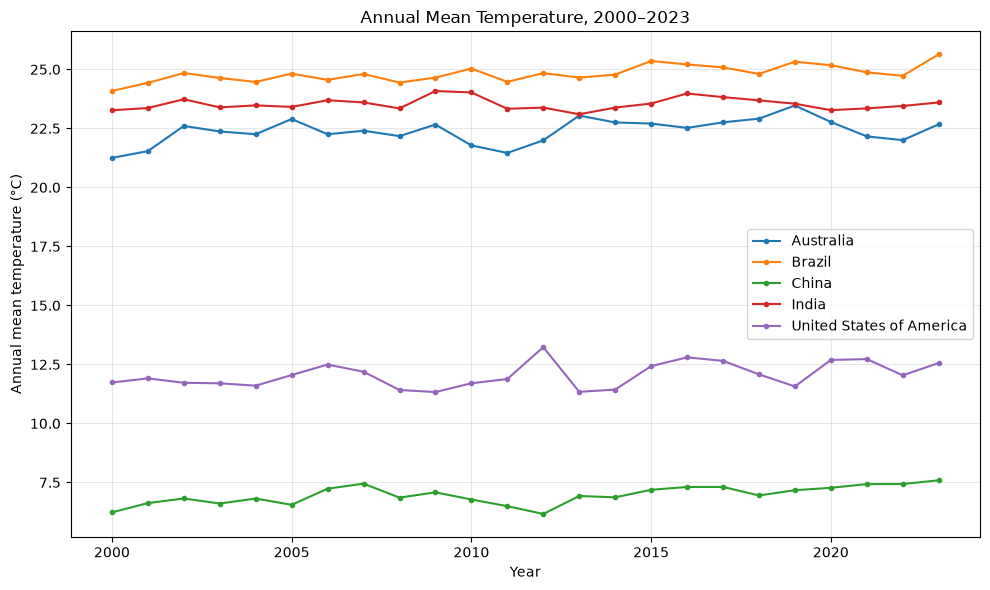

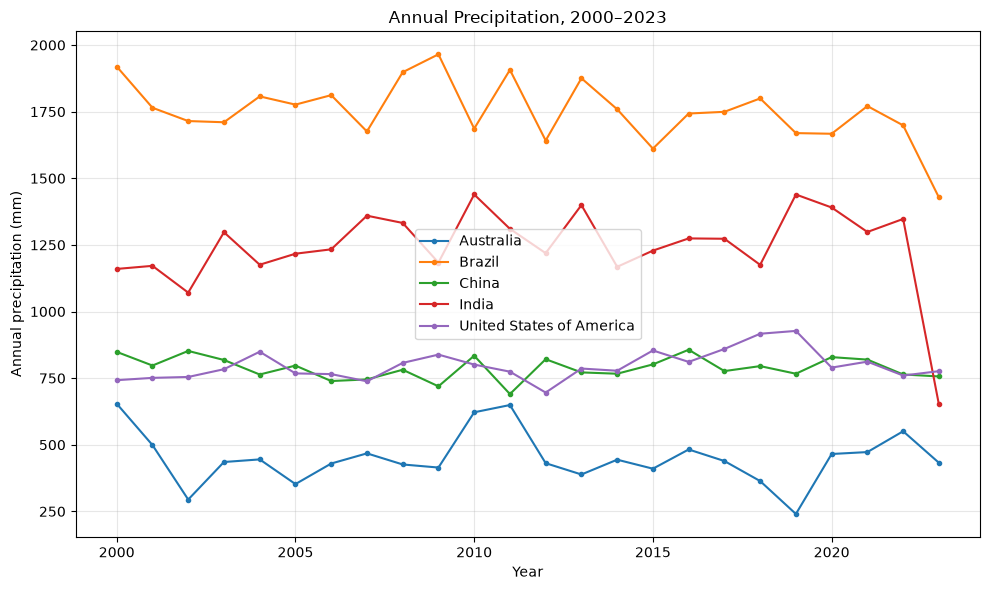

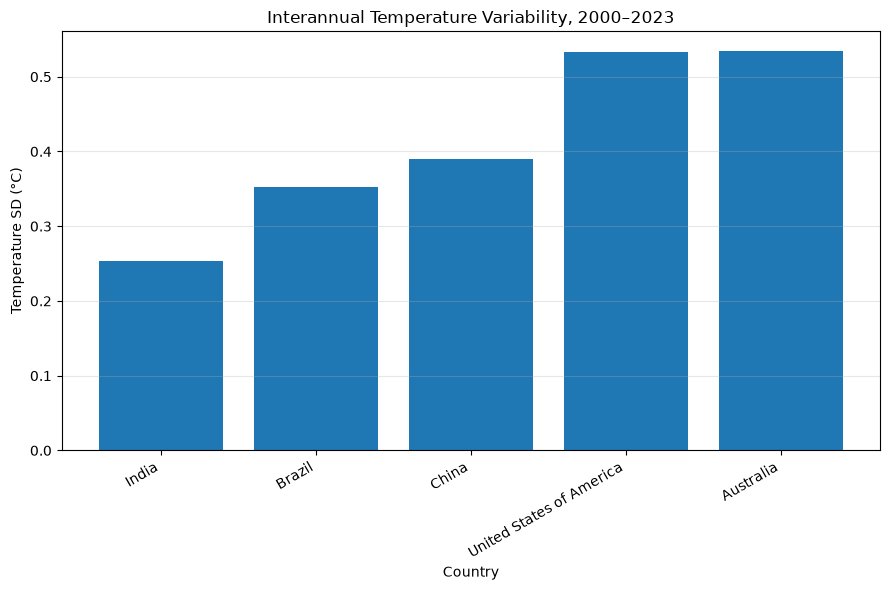

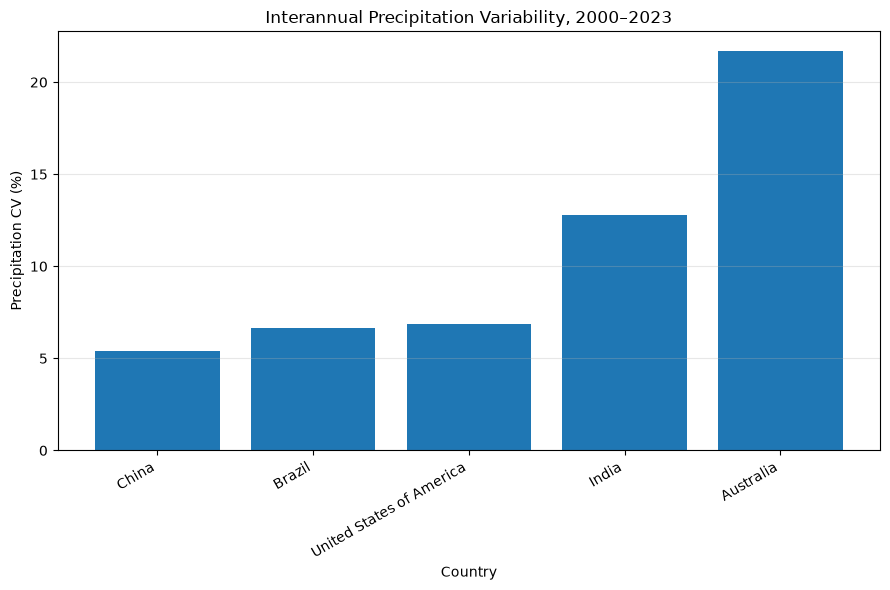

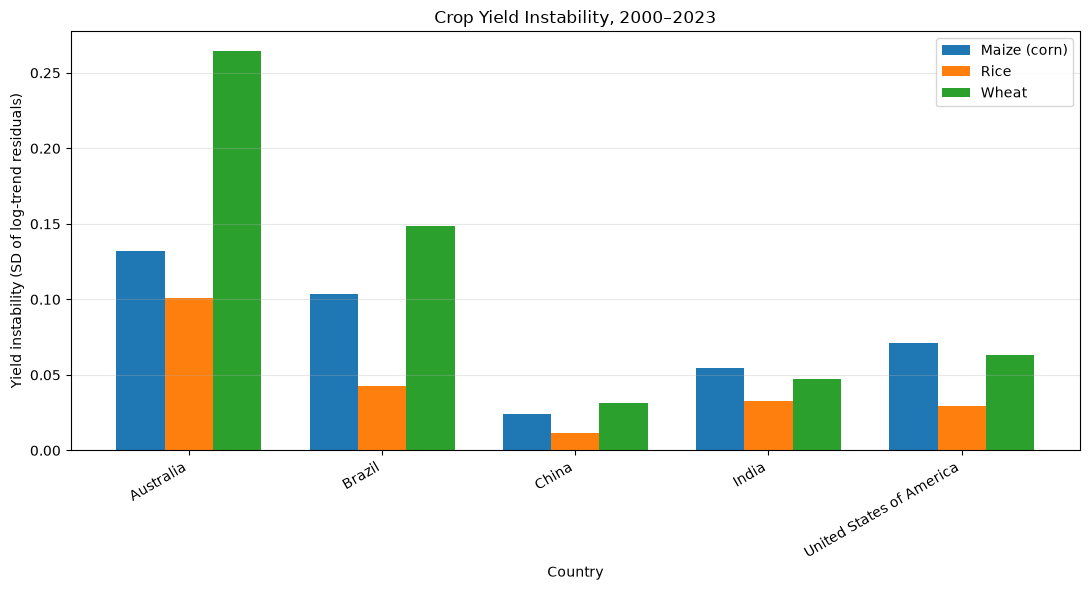

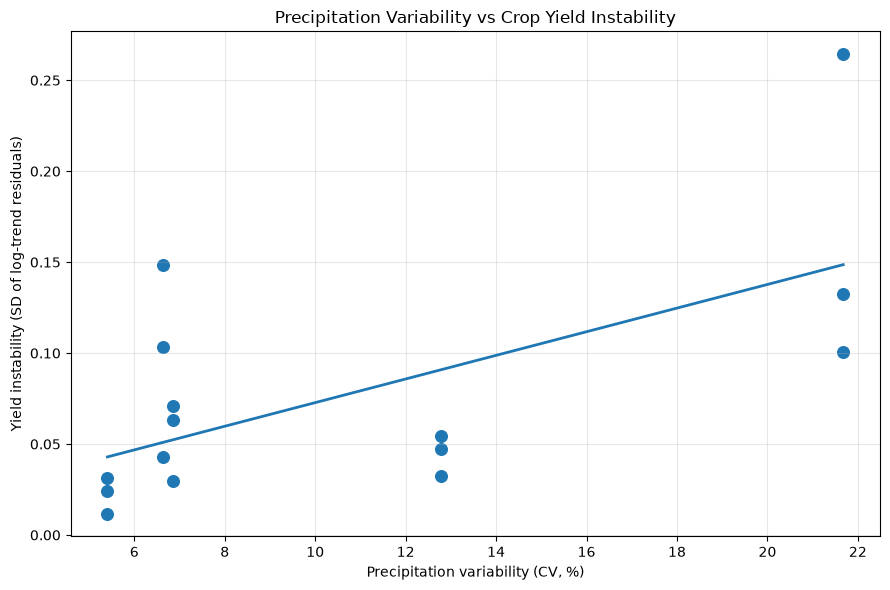

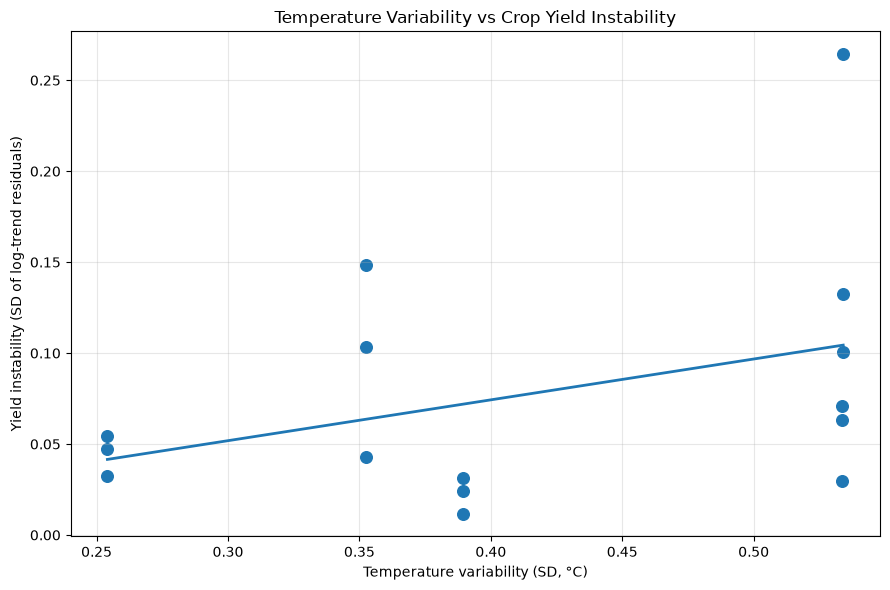

ALL REPORT-READY FIGURES SAVED
annual_precipitation_all_countries.png
annual_temperature_all_countries.png
precipitation_variability_by_country.png
precipitation_variability_vs_yield_instability.png
temperature_variability_by_country.png
temperature_variability_vs_yield_instability.png
yield_instability_by_country_crop.png


In [26]:
# ============================================================
# STEP 7 — REPORT-READY FIGURES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# ------------------------------------------------------------
# Load datasets
# ------------------------------------------------------------

climate_annual = pd.read_csv(
    "../results/report_ready/tables/"
    "climate_annual_all.csv"
)

climate_variability = pd.read_csv(
    "../results/report_ready/tables/"
    "climate_variability.csv"
)

yield_instability = pd.read_csv(
    "../results/report_ready/tables/"
    "yield_instability.csv"
)

merged = pd.read_csv(
    "../results/report_ready/tables/"
    "climate_yield_variability.csv"
)

# ------------------------------------------------------------
# Figure folder
# ------------------------------------------------------------

figure_dir = "../results/report_ready/figures"
os.makedirs(figure_dir, exist_ok=True)

# ============================================================
# FIGURE 1 — ANNUAL TEMPERATURE
# ============================================================

plt.figure(figsize=(10, 6))

for country in climate_annual["country"].unique():

    data = climate_annual[
        climate_annual["country"] == country
    ]

    plt.plot(
        data["year"],
        data["temperature_C"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=country
    )

plt.xlabel("Year")
plt.ylabel("Annual mean temperature (°C)")
plt.title(
    "Annual Mean Temperature, 2000–2023"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/annual_temperature_all_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 2 — ANNUAL PRECIPITATION
# ============================================================

plt.figure(figsize=(10, 6))

for country in climate_annual["country"].unique():

    data = climate_annual[
        climate_annual["country"] == country
    ]

    plt.plot(
        data["year"],
        data["precipitation_mm"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=country
    )

plt.xlabel("Year")
plt.ylabel("Annual precipitation (mm)")
plt.title(
    "Annual Precipitation, 2000–2023"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/annual_precipitation_all_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 3 — TEMPERATURE VARIABILITY
# ============================================================

plt.figure(figsize=(9, 6))

data = climate_variability.sort_values(
    "temperature_SD_C",
    ascending=True
)

plt.bar(
    data["country"],
    data["temperature_SD_C"]
)

plt.xlabel("Country")
plt.ylabel("Temperature SD (°C)")
plt.title(
    "Interannual Temperature Variability, 2000–2023"
)

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/temperature_variability_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 4 — PRECIPITATION VARIABILITY
# ============================================================

plt.figure(figsize=(9, 6))

data = climate_variability.sort_values(
    "precipitation_CV_percent",
    ascending=True
)

plt.bar(
    data["country"],
    data["precipitation_CV_percent"]
)

plt.xlabel("Country")
plt.ylabel("Precipitation CV (%)")
plt.title(
    "Interannual Precipitation Variability, 2000–2023"
)

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/precipitation_variability_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 5 — YIELD INSTABILITY BY COUNTRY AND CROP
# ============================================================

countries = yield_instability["country"].unique()
crops = yield_instability["crop"].unique()

x = np.arange(len(countries))
width = 0.25

plt.figure(figsize=(11, 6))

for i, crop in enumerate(crops):

    data = yield_instability[
        yield_instability["crop"] == crop
    ]

    # Make sure countries are in the same order
    data = data.set_index("country").loc[countries]

    plt.bar(
        x + (i - 1) * width,
        data["yield_instability_SD"],
        width,
        label=crop
    )

plt.xlabel("Country")
plt.ylabel("Yield instability (SD of log-trend residuals)")
plt.title(
    "Crop Yield Instability, 2000–2023"
)

plt.xticks(
    x,
    countries,
    rotation=30,
    ha="right"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/yield_instability_by_country_crop.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 6 — PRECIPITATION VARIABILITY VS YIELD INSTABILITY
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    merged["precipitation_CV_percent"],
    merged["yield_instability_SD"],
    s=70
)

# Linear trend line
x_values = merged["precipitation_CV_percent"]
y_values = merged["yield_instability_SD"]

slope, intercept = np.polyfit(
    x_values,
    y_values,
    1
)

x_line = np.linspace(
    x_values.min(),
    x_values.max(),
    100
)

y_line = (
    slope * x_line
    + intercept
)

plt.plot(
    x_line,
    y_line,
    linewidth=2
)

plt.xlabel(
    "Precipitation variability (CV, %)"
)

plt.ylabel(
    "Yield instability (SD of log-trend residuals)"
)

plt.title(
    "Precipitation Variability vs Crop Yield Instability"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/precipitation_variability_vs_yield_instability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FIGURE 7 — TEMPERATURE VARIABILITY VS YIELD INSTABILITY
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    merged["temperature_SD_C"],
    merged["yield_instability_SD"],
    s=70
)

# Linear trend line
x_values = merged["temperature_SD_C"]
y_values = merged["yield_instability_SD"]

slope, intercept = np.polyfit(
    x_values,
    y_values,
    1
)

x_line = np.linspace(
    x_values.min(),
    x_values.max(),
    100
)

y_line = (
    slope * x_line
    + intercept
)

plt.plot(
    x_line,
    y_line,
    linewidth=2
)

plt.xlabel(
    "Temperature variability (SD, °C)"
)

plt.ylabel(
    "Yield instability (SD of log-trend residuals)"
)

plt.title(
    "Temperature Variability vs Crop Yield Instability"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/temperature_variability_vs_yield_instability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# FINAL CHECK
# ============================================================

print("=" * 70)
print("ALL REPORT-READY FIGURES SAVED")
print("=" * 70)

for filename in sorted(os.listdir(figure_dir)):
    print(filename)

In [27]:
# ============================================================
# STEP 8 — SAVE MID-EVALUATION NOTES
# ============================================================

import os

notes_dir = "../results/report_ready/notes"
os.makedirs(notes_dir, exist_ok=True)

# ------------------------------------------------------------
# KEY RESULTS
# ------------------------------------------------------------

key_results = """
CLIMATE VARIABILITY AND CROP PRODUCTION STABILITY
MID-EVALUATION — PRELIMINARY RESULTS
===============================================================

Study design
------------
Countries: India, China, United States of America, Brazil, Australia
Crops: Rice, Wheat, Maize
Study period: 2000–2023

Climate variability
-------------------
Australia:
  Temperature SD: 0.534 °C
  Precipitation CV: 21.676 %

Brazil:
  Temperature SD: 0.352 °C
  Precipitation CV: 6.637 %

China:
  Temperature SD: 0.389 °C
  Precipitation CV: 5.405 %

India:
  Temperature SD: 0.254 °C
  Precipitation CV: 12.778 %

United States of America:
  Temperature SD: 0.533 °C
  Precipitation CV: 6.864 %

Exploratory relationships
-------------------------
Precipitation variability vs yield instability:
  Pearson r = 0.6198

Temperature variability vs yield instability:
  Pearson r = 0.3823

Interpretation
--------------
The preliminary country-crop analysis shows a positive association
between climate variability and crop-yield instability.

The association is stronger for precipitation variability
(r = 0.6198) than for temperature variability (r = 0.3823).

These results are exploratory and do not establish causality.

Important limitation
--------------------
The current analysis uses country-level climate variability and
country-crop yield instability over the full 2000–2023 period.

The final analysis should improve this using temporal/rolling
windows and, where possible, crop-specific growing-season climate.
"""


with open(
    f"{notes_dir}/key_results.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(key_results)


# ------------------------------------------------------------
# METHODOLOGY SUMMARY
# ------------------------------------------------------------

methodology_summary = """
METHODOLOGY SUMMARY
===================

1. STUDY DESIGN
---------------
Five countries were selected:
India, China, United States of America, Brazil and Australia.

Three crops were analysed:
Rice, Wheat and Maize.

The working study period is 2000–2023.

2. CROP YIELD DATA
------------------
Crop yield data were obtained from FAOSTAT.

The cleaned dataset contains:
5 countries × 3 crops × 24 years = 360 observations.

Yield is measured in kg/ha.

For each country-crop series:
- yield was log-transformed
- a linear time trend was fitted
- residuals from the trend were calculated
- the standard deviation of the residuals was used as the
  preliminary measure of yield instability

3. CLIMATE DATA
---------------
Climate data were obtained from ERA5-Land.

Variables:
- 2 metre temperature
- total precipitation

Monthly country-level values were calculated using a
geographical country mask and cosine-latitude weighting.

Annual temperature:
mean of monthly temperatures.

Annual precipitation:
sum of monthly precipitation.

4. CLIMATE VARIABILITY
----------------------
Temperature variability:
standard deviation of annual temperature.

Precipitation variability:
coefficient of variation (CV) of annual precipitation.

CV = standard deviation / mean × 100

5. DATA VALIDATION
------------------
ERA5-Land precipitation data for the affected late-2022/2023
period were corrected using the appropriate monthly-averaged
ERA5-Land product.

The corrected monthly dataset was then used to rebuild the
annual climate dataset and all precipitation-dependent results.

6. EXPLORATORY ANALYSIS
-----------------------
The climate variability table was merged with the
country-crop yield instability table.

This produced:
5 countries × 3 crops = 15 country-crop observations.

Pearson correlations were calculated between:
- precipitation variability and yield instability
- temperature variability and yield instability

7. INTERPRETATION
-----------------
The current results are exploratory.

A positive correlation indicates that higher climate variability
is associated with higher yield instability in this dataset.

Correlation does not establish causation.

8. FUTURE / FINAL ANALYSIS
--------------------------
The final analysis should extend the current work by considering:
- rolling 10-year climate variability
- rolling 10-year yield instability
- crop-specific growing-season climate
- additional robustness checks
- appropriate statistical/panel modelling
"""


with open(
    f"{notes_dir}/methodology_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(methodology_summary)


print("=" * 70)
print("MID-EVALUATION NOTES SAVED")
print("=" * 70)

print(f"{notes_dir}/key_results.txt")
print(f"{notes_dir}/methodology_summary.txt")

MID-EVALUATION NOTES SAVED
../results/report_ready/notes/key_results.txt
../results/report_ready/notes/methodology_summary.txt


In [28]:
# ============================================================
# STEP 9 — ERA5 PRECIPITATION VALIDATION TABLE
# ============================================================

import pandas as pd
import os

# Validation results obtained from the corrected ERA5 check
validation = pd.DataFrame({
    "country": [
        "India",
        "China",
        "United States of America",
        "Brazil",
        "Australia"
    ],
    "validation_period": [
        "Jan-Aug 2022",
        "Jan-Aug 2022",
        "Jan-Aug 2022",
        "Jan-Aug 2022",
        "Jan-Aug 2022"
    ],
    "mean_absolute_difference_mm": [
        0.00,
        0.00,
        0.00,
        0.00,
        0.00
    ],
    "mean_absolute_percentage_difference_percent": [
        0.00,
        0.00,
        0.00,
        0.00,
        0.00
    ],
    "corrected_2022_annual_precipitation_mm": [
        1347.46,
        763.83,
        759.85,
        1698.61,
        550.76
    ],
    "corrected_2023_annual_precipitation_mm": [
        1057.88,
        756.42,
        776.22,
        1428.31,
        432.51
    ]
})

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_path = (
    "../results/report_ready/tables/"
    "era5_precipitation_validation.csv"
)

validation.to_csv(
    output_path,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 90)
print("ERA5 PRECIPITATION VALIDATION")
print("=" * 90)

print(
    validation.to_string(index=False)
)

print("\nSaved:")
print(output_path)

ERA5 PRECIPITATION VALIDATION
                 country validation_period  mean_absolute_difference_mm  mean_absolute_percentage_difference_percent  corrected_2022_annual_precipitation_mm  corrected_2023_annual_precipitation_mm
                   India      Jan-Aug 2022                          0.0                                          0.0                                 1347.46                                 1057.88
                   China      Jan-Aug 2022                          0.0                                          0.0                                  763.83                                  756.42
United States of America      Jan-Aug 2022                          0.0                                          0.0                                  759.85                                  776.22
                  Brazil      Jan-Aug 2022                          0.0                                          0.0                                 1698.61                          